# IMC Prosperity 4 — Round 5: 50-Product Deep Analysis
## Sector Clustering, ETF Construction, Spread Studies & Pair Trading

**Data**: Days 2, 3, 4 — 50 products across 10 sectors (5 products each)  
**Key early finding**: Most sectors have **negative** average intra-correlation → zero-sum / rotation dynamics.

---

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from scipy.spatial.distance import squareform
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from itertools import combinations
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (16, 8)
plt.rcParams['figure.dpi'] = 100
sns.set_style('darkgrid')

# ═══ Load data ═══════════════════════════════════════════
DATA_DIR = "DATA_DIR"  # ← CHANGE THIS to your local data folder

dfs = []
for day in [2, 3, 4]:
    df = pd.read_csv(f"{DATA_DIR}/prices_round_5_day_{day}.csv", sep=';')
    dfs.append(df)
raw = pd.concat(dfs, ignore_index=True)

# Mid-price pivot: rows = (day, timestamp), columns = products
raw['time_id'] = raw['day'].astype(str) + '_' + raw['timestamp'].astype(str)
mid = raw.pivot_table(index='time_id', columns='product', values='mid_price')
mid = mid.sort_index()

print(f"Shape: {mid.shape}  ({mid.shape[0]} timestamps × {mid.shape[1]} products)")
print(f"Days loaded: {sorted(raw['day'].unique())}")
print(f"Timestamps per day: {mid.shape[0] // len(raw['day'].unique())}")
mid.head()

Shape: (30000, 50)  (30000 timestamps × 50 products)
Days loaded: [np.int64(2), np.int64(3), np.int64(4)]
Timestamps per day: 10000


product,GALAXY_SOUNDS_BLACK_HOLES,GALAXY_SOUNDS_DARK_MATTER,GALAXY_SOUNDS_PLANETARY_RINGS,GALAXY_SOUNDS_SOLAR_FLAMES,GALAXY_SOUNDS_SOLAR_WINDS,MICROCHIP_CIRCLE,MICROCHIP_OVAL,MICROCHIP_RECTANGLE,MICROCHIP_SQUARE,MICROCHIP_TRIANGLE,...,TRANSLATOR_ASTRO_BLACK,TRANSLATOR_ECLIPSE_CHARCOAL,TRANSLATOR_GRAPHITE_MIST,TRANSLATOR_SPACE_GRAY,TRANSLATOR_VOID_BLUE,UV_VISOR_AMBER,UV_VISOR_MAGENTA,UV_VISOR_ORANGE,UV_VISOR_RED,UV_VISOR_YELLOW
time_id,,,,,,,,,,,,,,,,,,,,,
2_0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,...,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0
2_100,10007.5,9988.5,9988.5,10002.5,10000.5,9991.5,9999.5,9999.5,9999.5,10000.5,...,9986.5,10015.5,10006.5,10000.5,10002.5,10014.0,10009.5,10003.5,10004.5,9989.5
2_1000,9968.5,9986.5,9968.5,10017.5,10067.5,9989.5,9996.5,10003.5,9997.5,10002.5,...,9996.5,10001.5,10018.5,10011.5,10022.5,10019.5,10040.5,10044.5,9980.5,9959.5
2_10000,9792.0,9869.5,9942.5,10067.5,9977.5,10009.5,9891.5,10014.5,10014.5,9983.5,...,10094.5,10048.5,9930.5,9942.5,10043.5,9803.5,9994.5,10021.5,10051.5,10074.5
2_100000,9910.5,9872.5,10246.5,10488.5,10144.5,9253.5,9945.5,9855.5,9831.5,10012.5,...,10049.5,9593.5,10121.5,10058.5,10057.5,9850.5,10219.5,10052.5,10783.0,10001.5


In [3]:
import sys, subprocess

print(sys.executable)

subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "seaborn"
])

.venv/bin/python
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)


0

---
## 1. Sector Mapping & Product Inventory

In [5]:
def get_sector(name):
    prefixes = ['GALAXY_SOUNDS', 'MICROCHIP', 'OXYGEN_SHAKE', 'PANEL', 'PEBBLES',
                'ROBOT', 'SLEEP_POD', 'SNACKPACK', 'TRANSLATOR', 'UV_VISOR']
    for sec in prefixes:
        if name.startswith(sec):
            return sec
    return 'UNKNOWN'

products = sorted(mid.columns)
sector_map = {p: get_sector(p) for p in products}
sectors = sorted(set(sector_map.values()))

print(f"Total products: {len(products)}")
print(f"Total sectors: {len(sectors)}\n")
for s in sectors:
    members = [p for p in products if sector_map[p] == s]
    variants = [m.replace(s + '_', '') for m in members]
    print(f"  {s:25s} → {variants}")

Total products: 50
Total sectors: 10

  GALAXY_SOUNDS             → ['BLACK_HOLES', 'DARK_MATTER', 'PLANETARY_RINGS', 'SOLAR_FLAMES', 'SOLAR_WINDS']
  MICROCHIP                 → ['CIRCLE', 'OVAL', 'RECTANGLE', 'SQUARE', 'TRIANGLE']
  OXYGEN_SHAKE              → ['CHOCOLATE', 'EVENING_BREATH', 'GARLIC', 'MINT', 'MORNING_BREATH']
  PANEL                     → ['1X2', '1X4', '2X2', '2X4', '4X4']
  PEBBLES                   → ['L', 'M', 'S', 'XL', 'XS']
  ROBOT                     → ['DISHES', 'IRONING', 'LAUNDRY', 'MOPPING', 'VACUUMING']
  SLEEP_POD                 → ['COTTON', 'LAMB_WOOL', 'NYLON', 'POLYESTER', 'SUEDE']
  SNACKPACK                 → ['CHOCOLATE', 'PISTACHIO', 'RASPBERRY', 'STRAWBERRY', 'VANILLA']
  TRANSLATOR                → ['ASTRO_BLACK', 'ECLIPSE_CHARCOAL', 'GRAPHITE_MIST', 'SPACE_GRAY', 'VOID_BLUE']
  UV_VISOR                  → ['AMBER', 'MAGENTA', 'ORANGE', 'RED', 'YELLOW']


---
## 2. Descriptive Statistics — Price & Return Characteristics

In [6]:
returns = mid.pct_change().dropna()

desc = pd.DataFrame({
    'sector': [sector_map[c] for c in mid.columns],
    'mean_price': mid.mean(),
    'std_price': mid.std(),
    'cv_price': mid.std() / mid.mean(),
    'mean_ret': returns.mean(),
    'std_ret': returns.std(),
    'skew_ret': returns.skew(),
    'kurt_ret': returns.kurt(),
    'range_pct': (mid.max() - mid.min()) / mid.mean() * 100
}).sort_values(['sector', 'cv_price'])

print("═══ Product Statistics (sorted by sector → coefficient of variation) ═══\n")
for s in sectors:
    sub = desc[desc['sector'] == s]
    print(f"\n  ── {s} ──")
    print(sub[['mean_price', 'std_price', 'cv_price', 'std_ret', 'range_pct']].to_string())

═══ Product Statistics (sorted by sector → coefficient of variation) ═══


  ── GALAXY_SOUNDS ──
                                 mean_price   std_price  cv_price   std_ret  range_pct
product                                                                               
GALAXY_SOUNDS_DARK_MATTER      10226.661817  330.700516  0.032337  0.024092  16.085405
GALAXY_SOUNDS_SOLAR_FLAMES     11092.571700  450.150431  0.040581  0.029783  21.388187
GALAXY_SOUNDS_SOLAR_WINDS      10437.543967  541.110756  0.051843  0.029286  21.973560
GALAXY_SOUNDS_PLANETARY_RINGS  10766.673183  765.836693  0.071130  0.022797  27.204318
GALAXY_SOUNDS_BLACK_HOLES      11466.872083  958.444676  0.083584  0.032672  39.492025

  ── MICROCHIP ──
                       mean_price    std_price  cv_price   std_ret  range_pct
product                                                                      
MICROCHIP_CIRCLE      9214.885283   532.512209  0.057788  0.039754  26.348673
MICROCHIP_TRIANGLE    9686.391083   833.3

---
## 3. Sector-Level Volatility Ranking

In [7]:
sector_stats = desc.groupby('sector').agg(
    avg_cv=('cv_price', 'mean'),
    avg_std_ret=('std_ret', 'mean'),
    min_cv=('cv_price', 'min'),
    max_cv=('cv_price', 'max'),
    cv_spread=('cv_price', lambda x: x.max() - x.min()),
    avg_range_pct=('range_pct', 'mean'),
).sort_values('avg_cv')

print("═══ Sector Volatility Ranking (low → high) ═══\n")
print(sector_stats.to_string())
print()
print("INTERPRETATION:")
print("  • Lowest avg CV → SNACKPACK, TRANSLATOR → tightest price ranges")
print("  • Highest cv_spread → MICROCHIP, PEBBLES → most internal dispersion")
print("  • High dispersion = bigger spread opportunities within sector")

═══ Sector Volatility Ranking (low → high) ═══

                 avg_cv  avg_std_ret    min_cv    max_cv  cv_spread  avg_range_pct
sector                                                                            
SNACKPACK      0.021725     0.010384  0.016850  0.033958   0.017108      11.536962
TRANSLATOR     0.048920     0.026383  0.036239  0.053345   0.017107      21.742593
GALAXY_SOUNDS  0.055895     0.027726  0.032337  0.083584   0.051247      25.228699
OXYGEN_SHAKE   0.059730     0.035131  0.043122  0.079941   0.036819      27.391867
PANEL          0.065453     0.029074  0.046265  0.088750   0.042485      27.294841
SLEEP_POD      0.065985     0.026177  0.038609  0.082559   0.043950      27.543308
ROBOT          0.066843     0.026082  0.055562  0.088608   0.033046      25.386052
UV_VISOR       0.069875     0.028361  0.052808  0.126006   0.073197      27.415122
PEBBLES        0.110312     0.052419  0.061168  0.195762   0.134594      47.786228
MICROCHIP      0.110860     0.043726  0

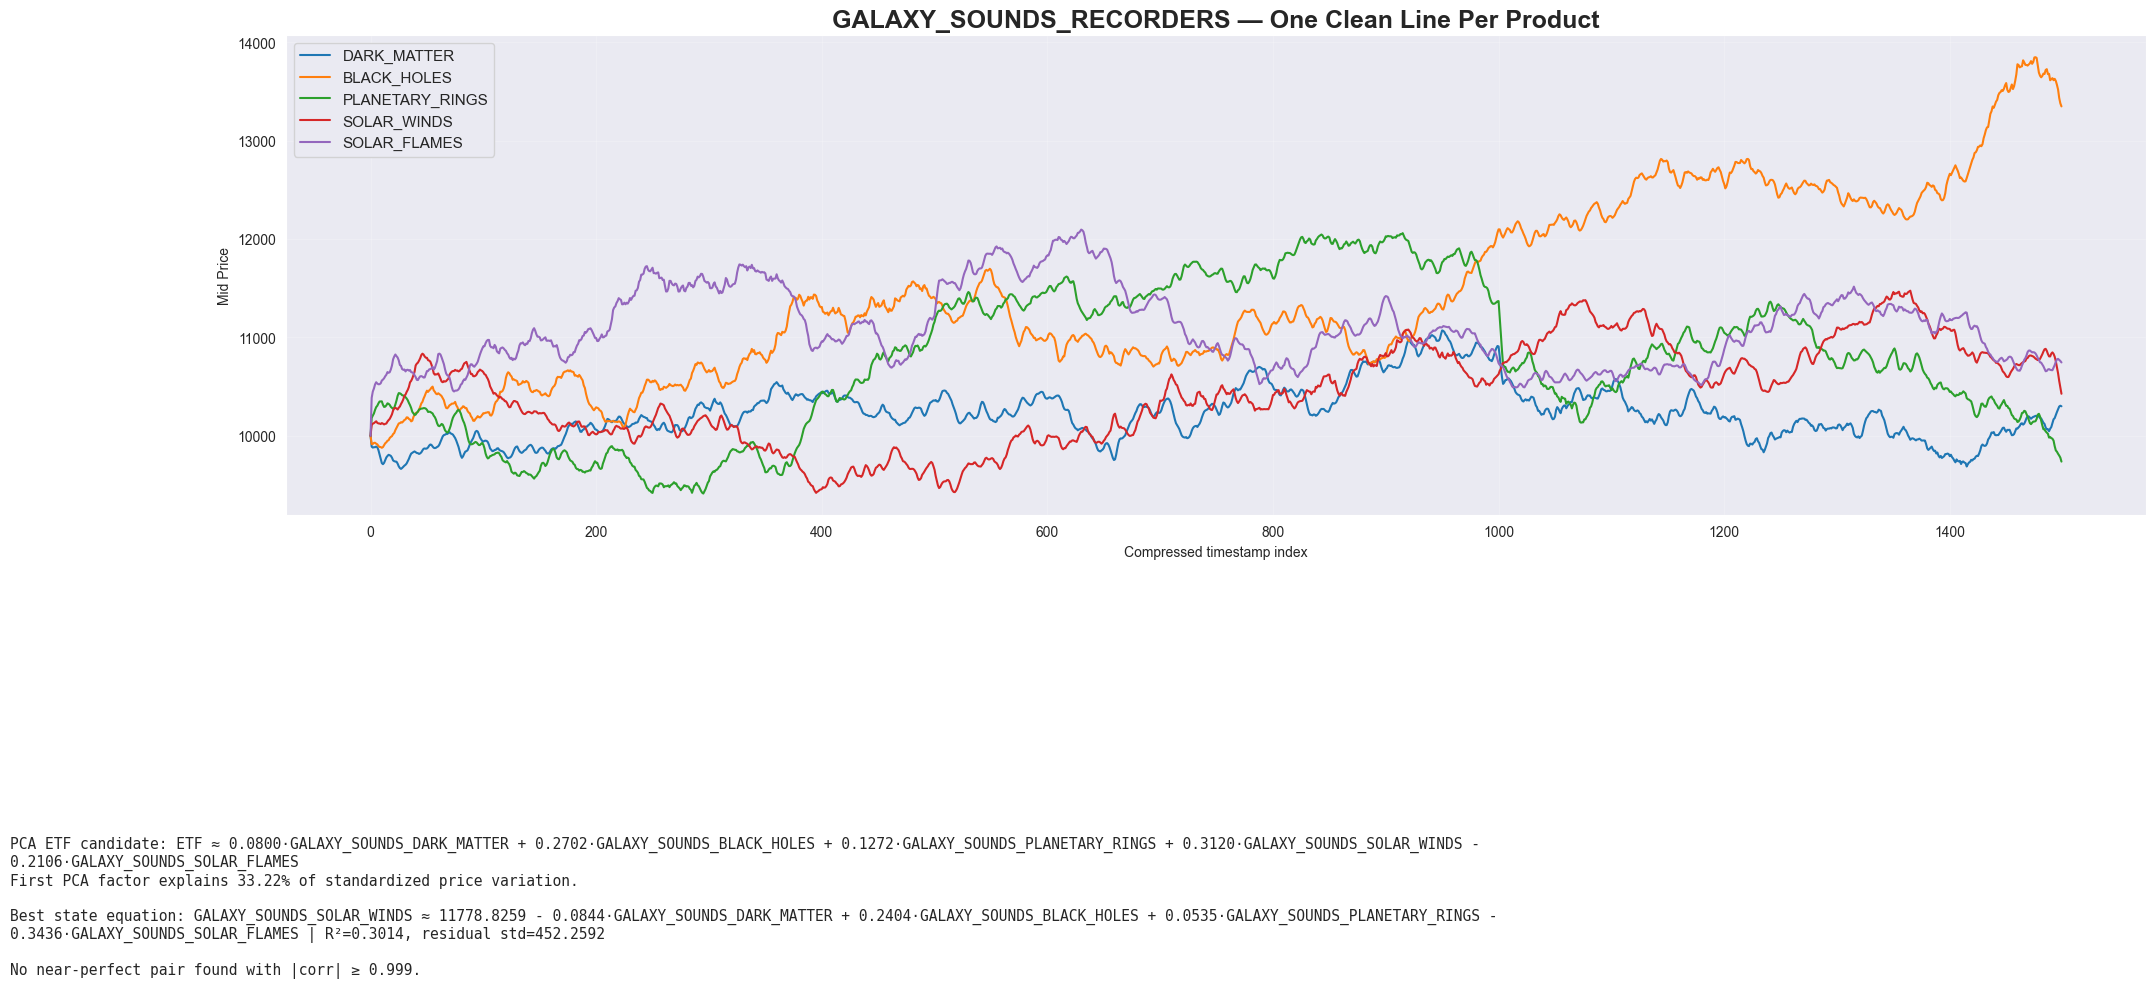

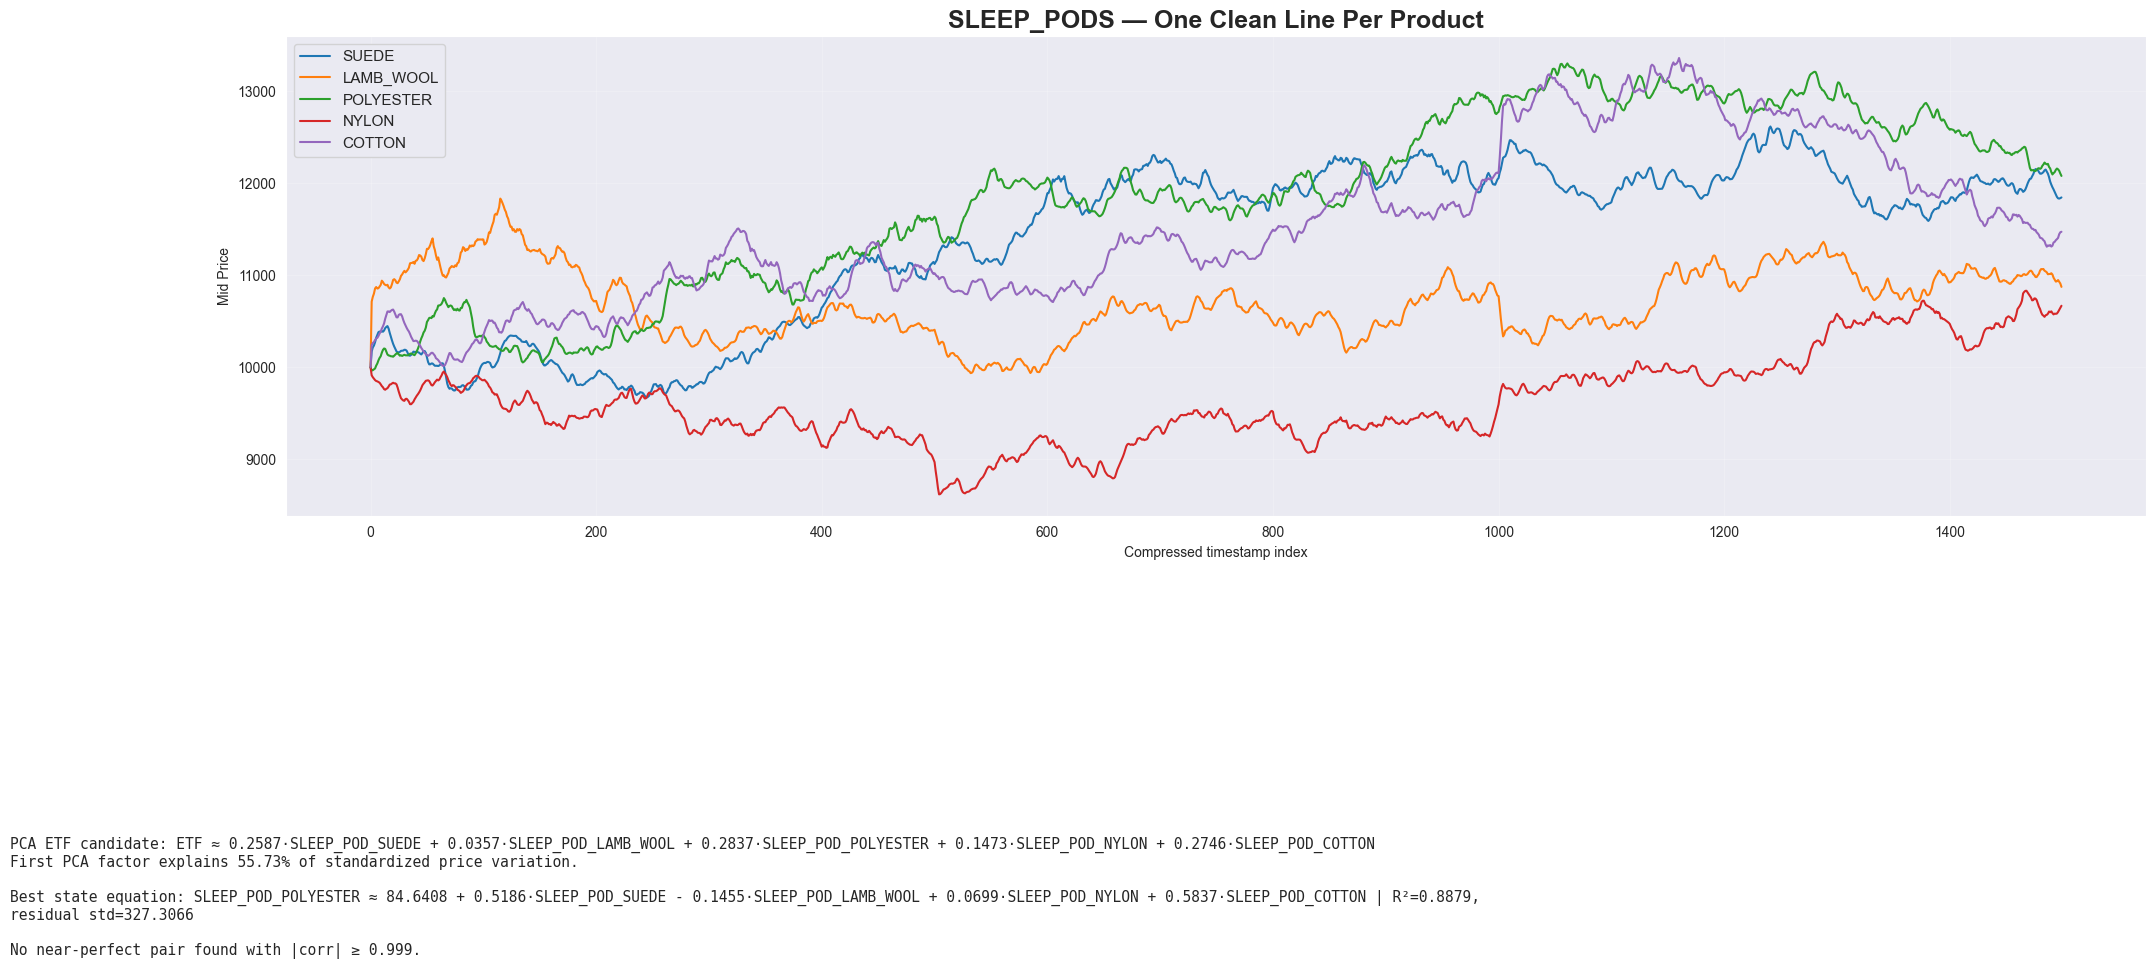

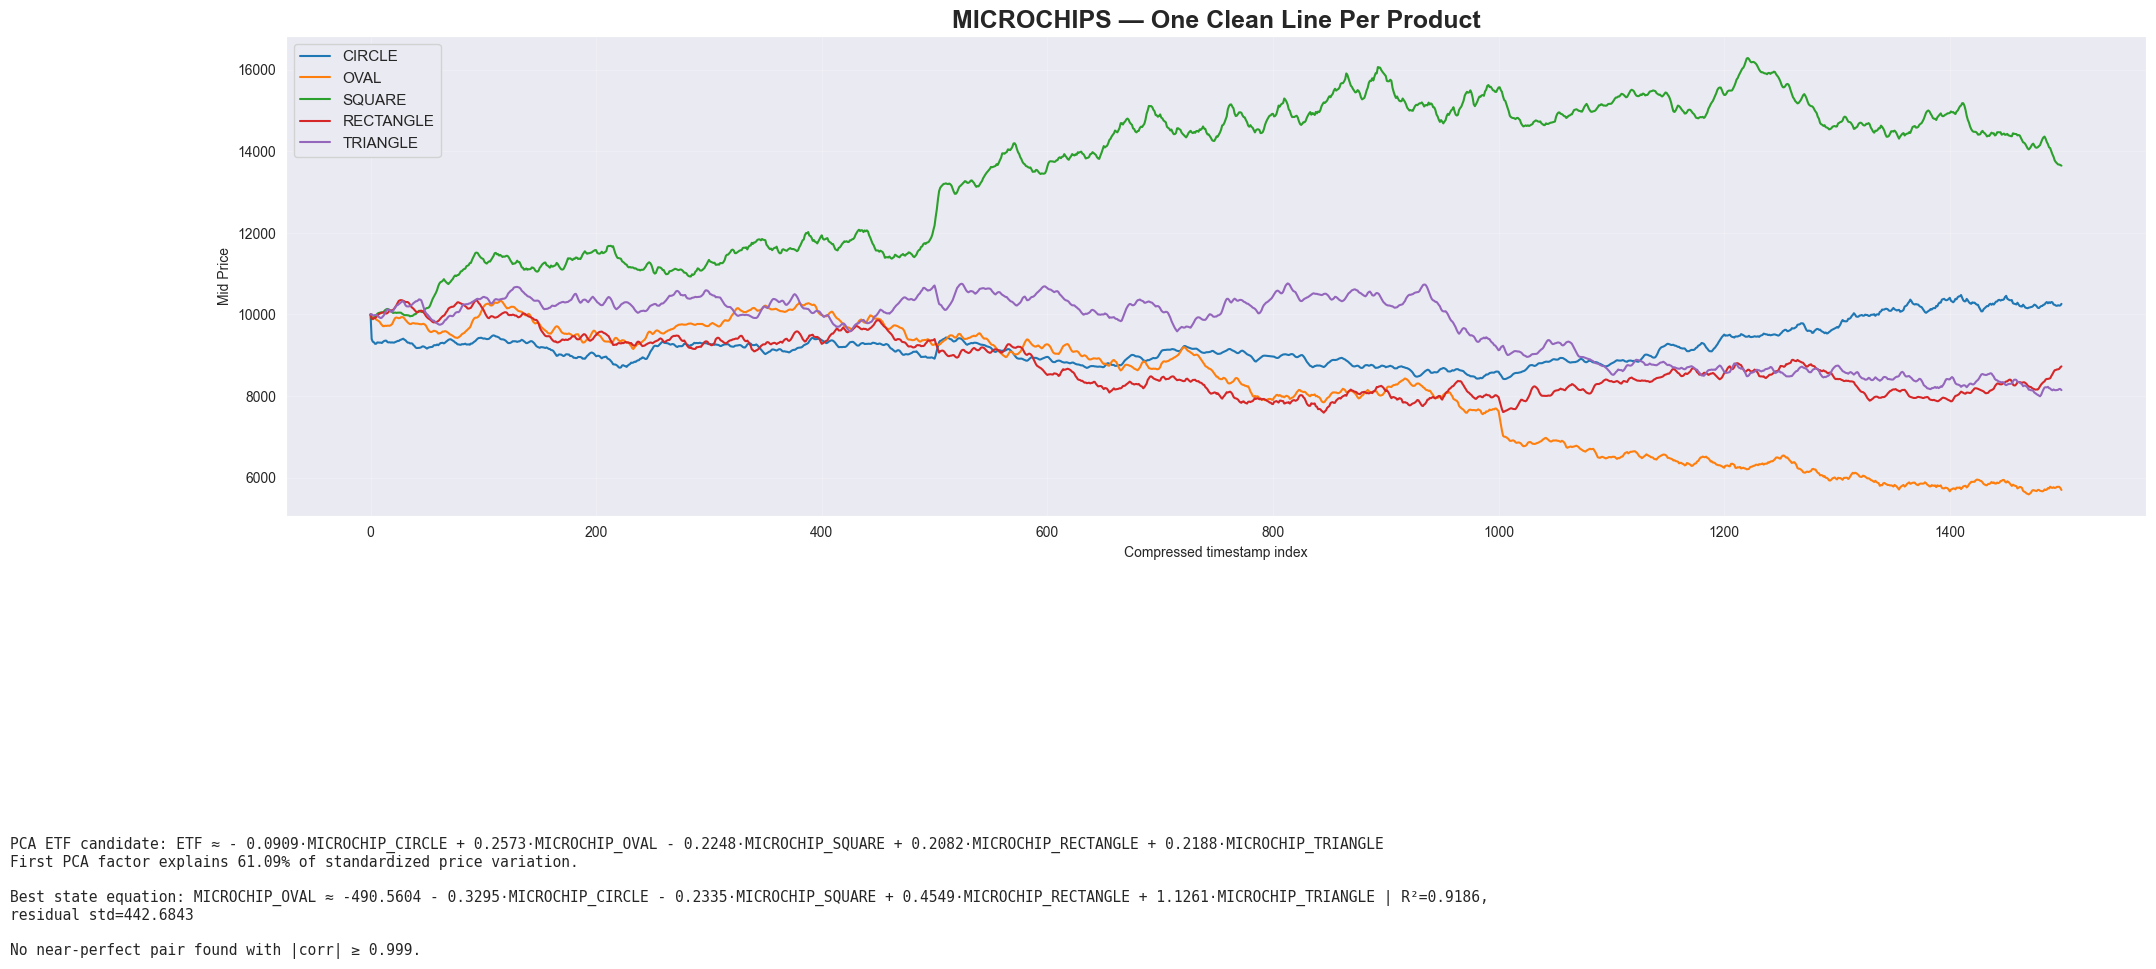

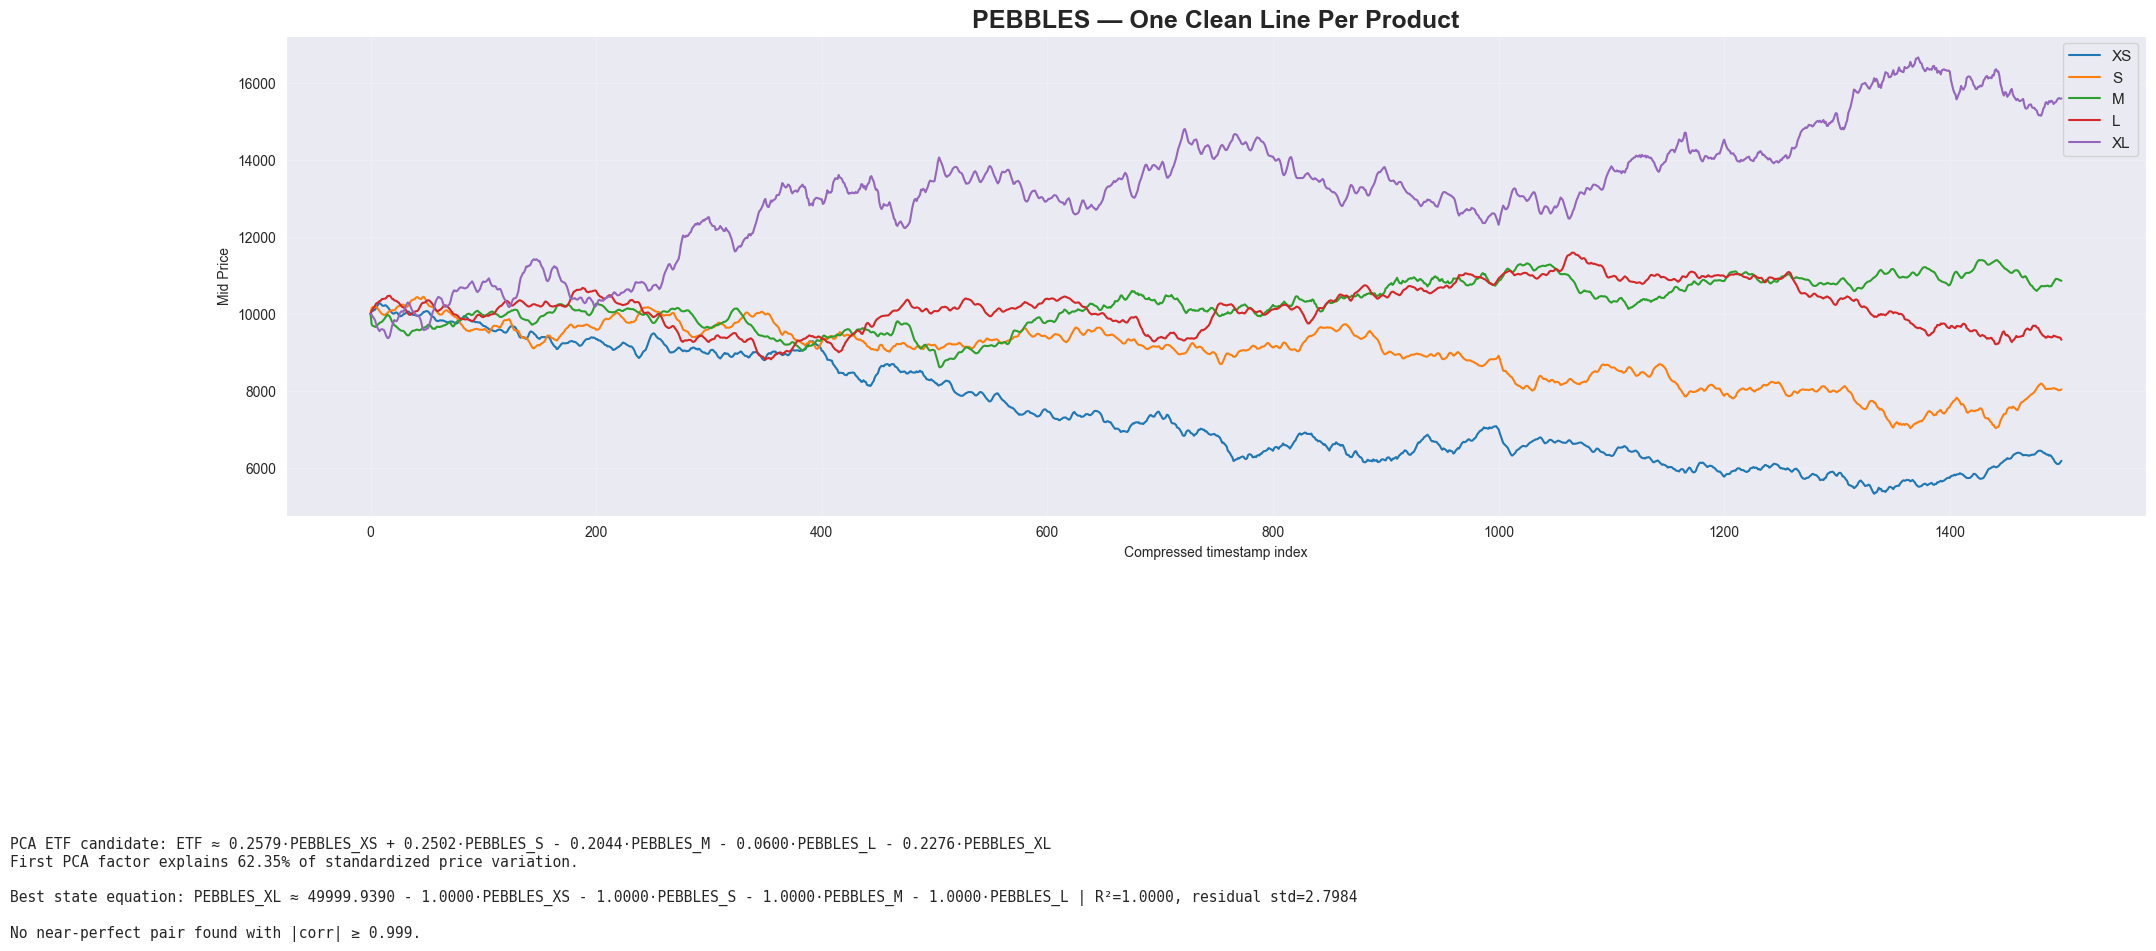

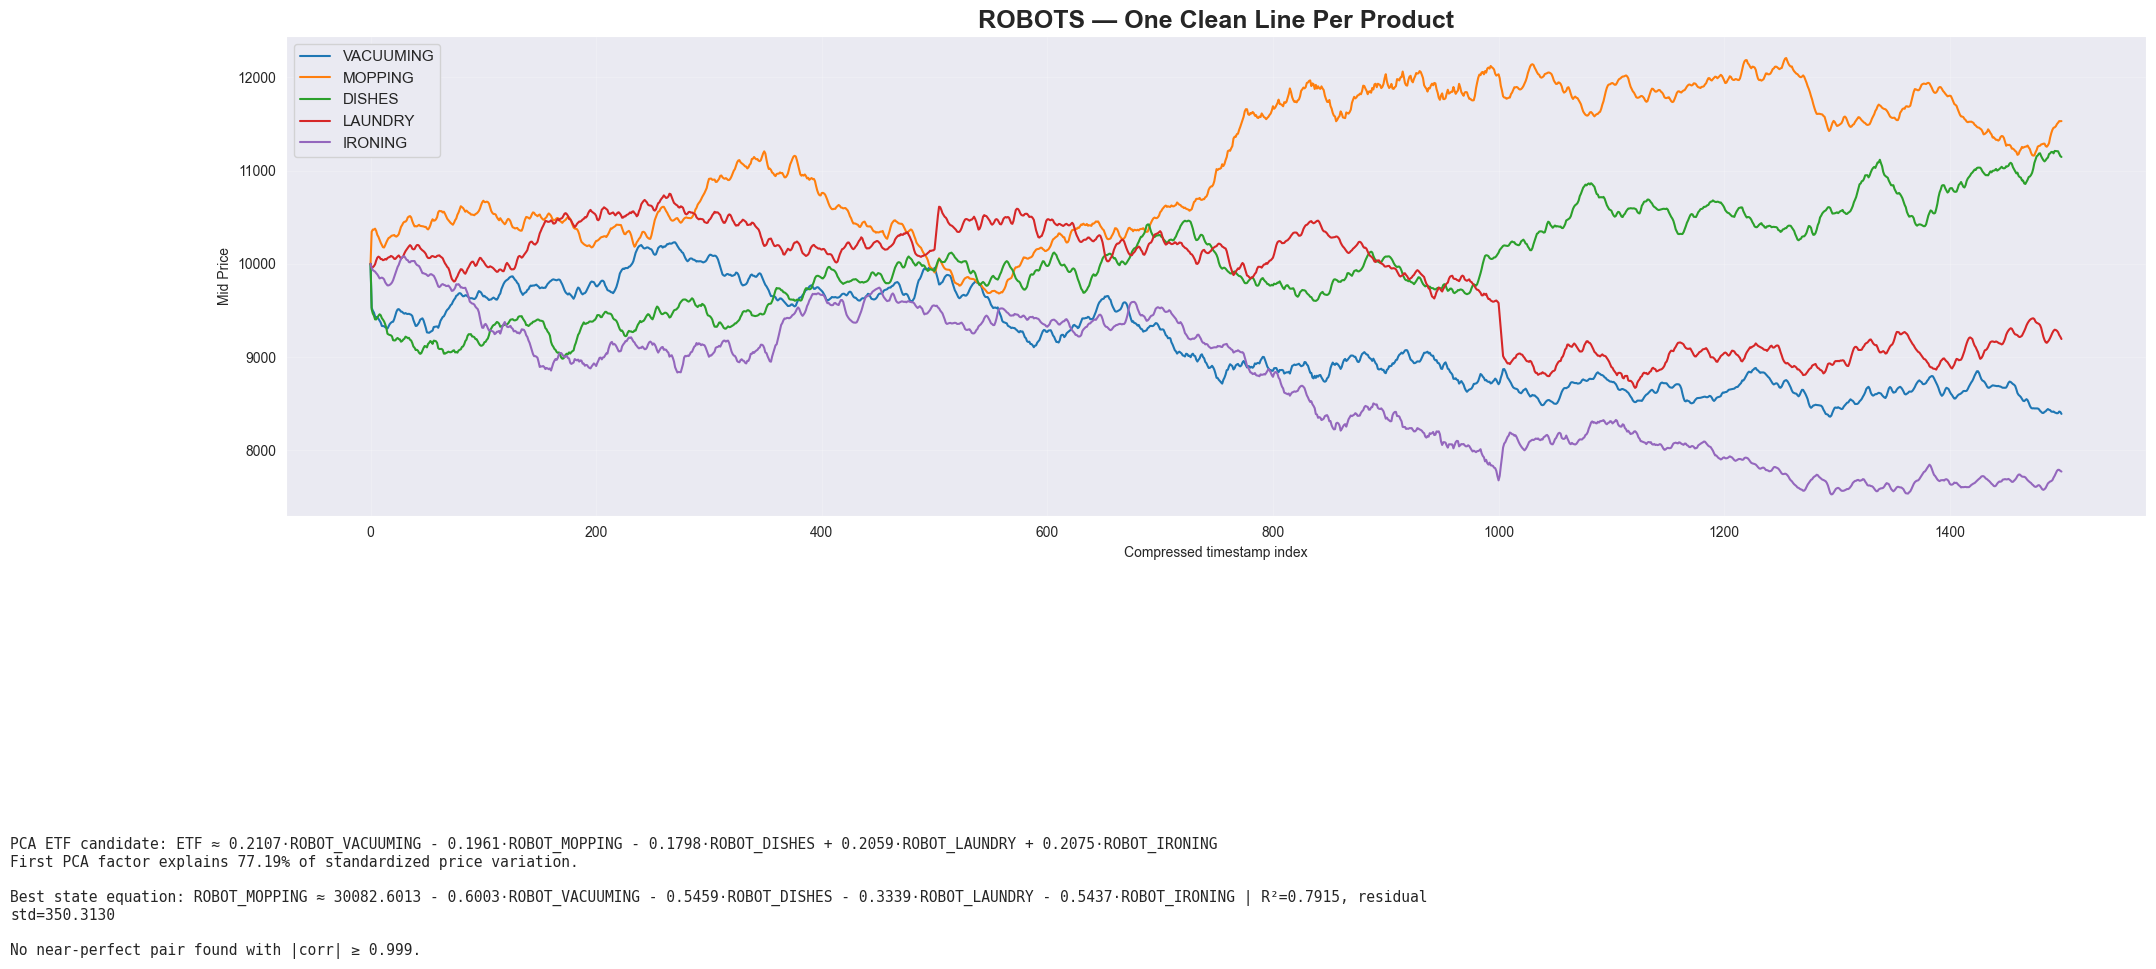

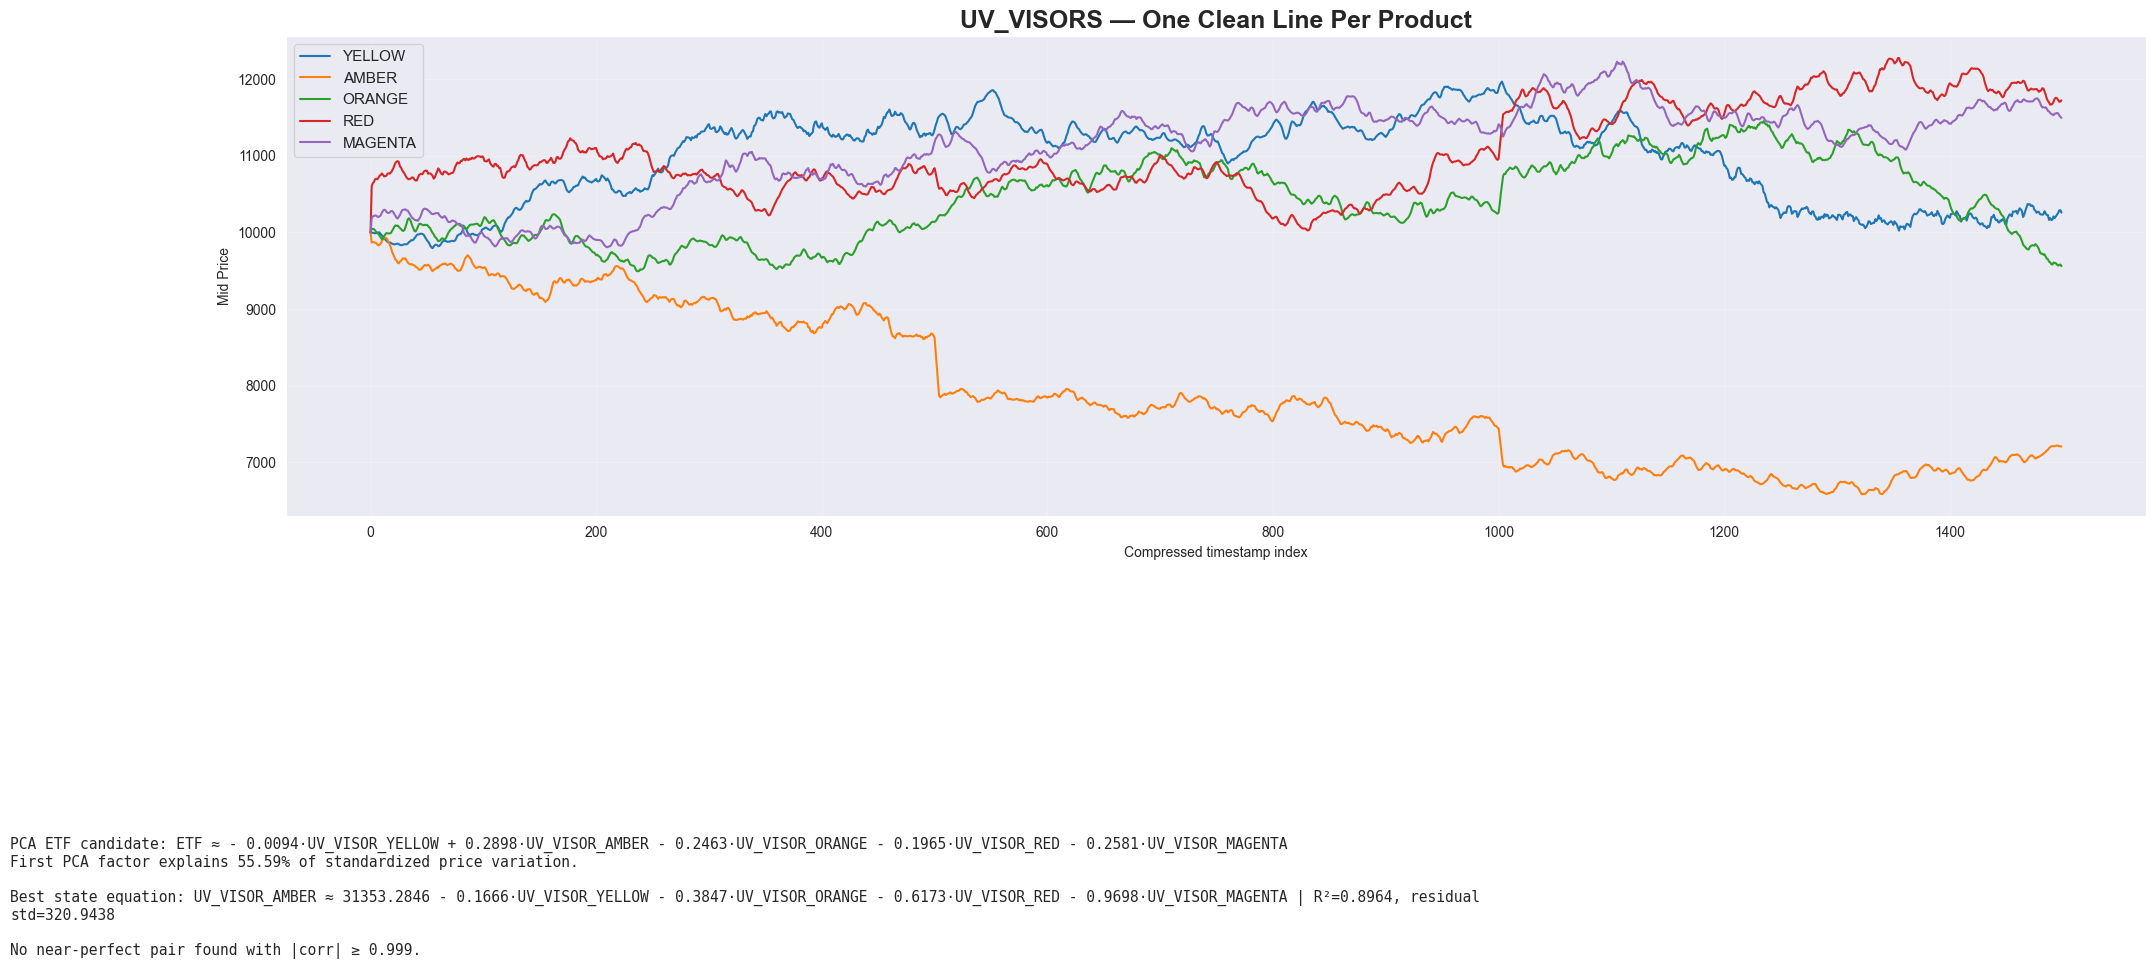

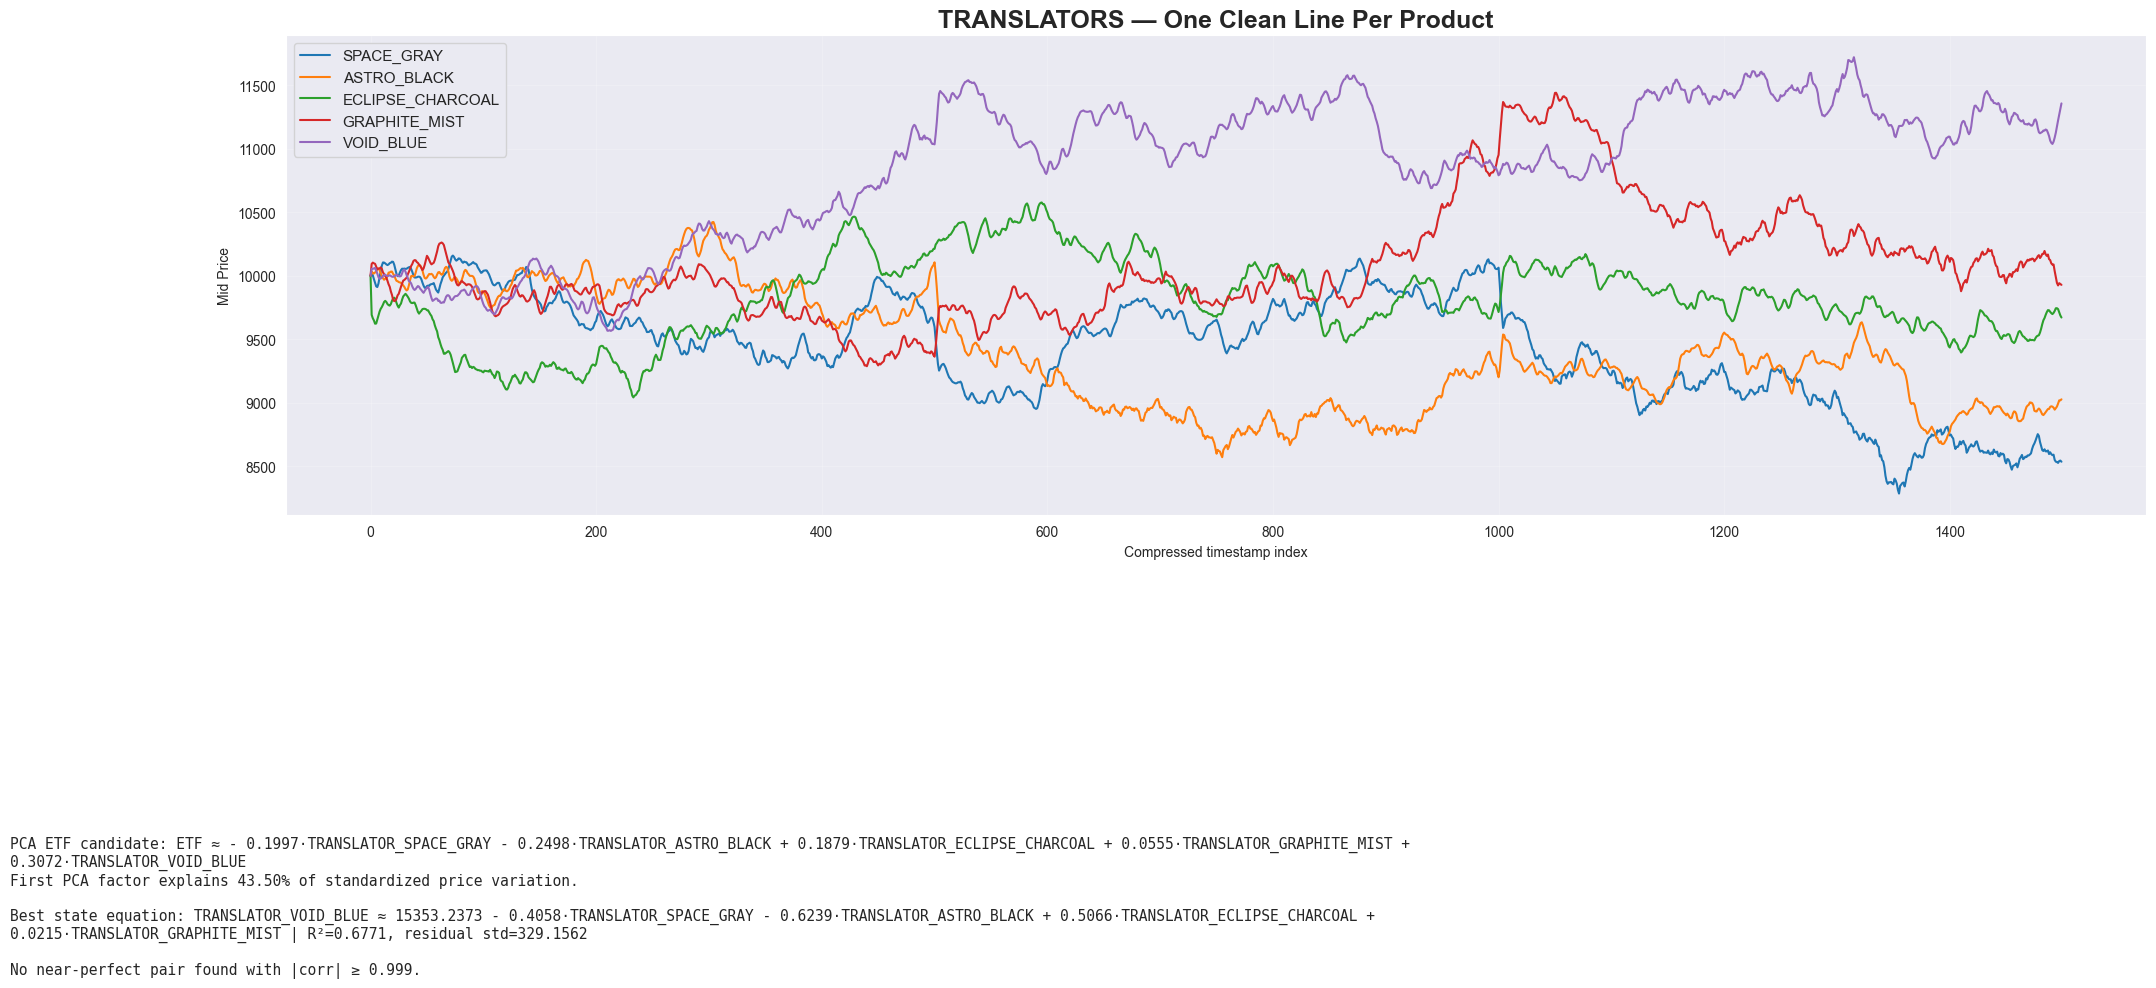

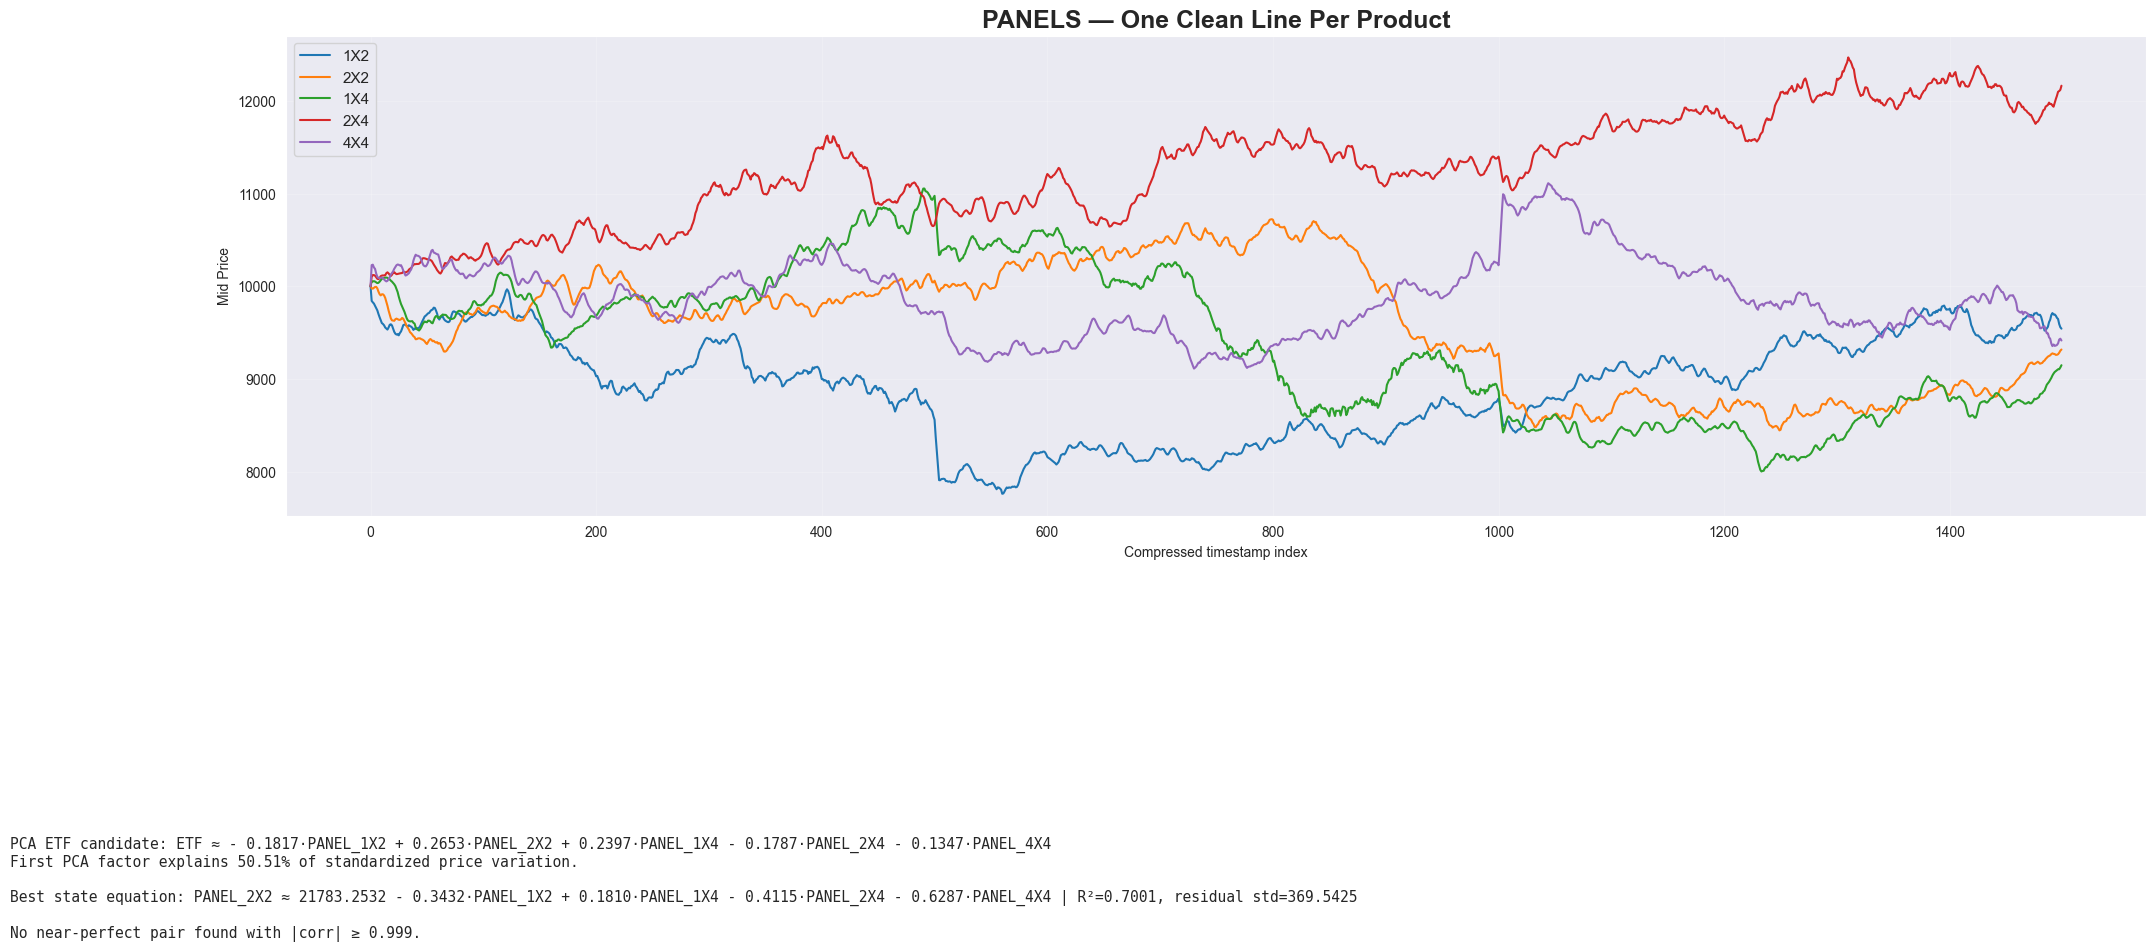

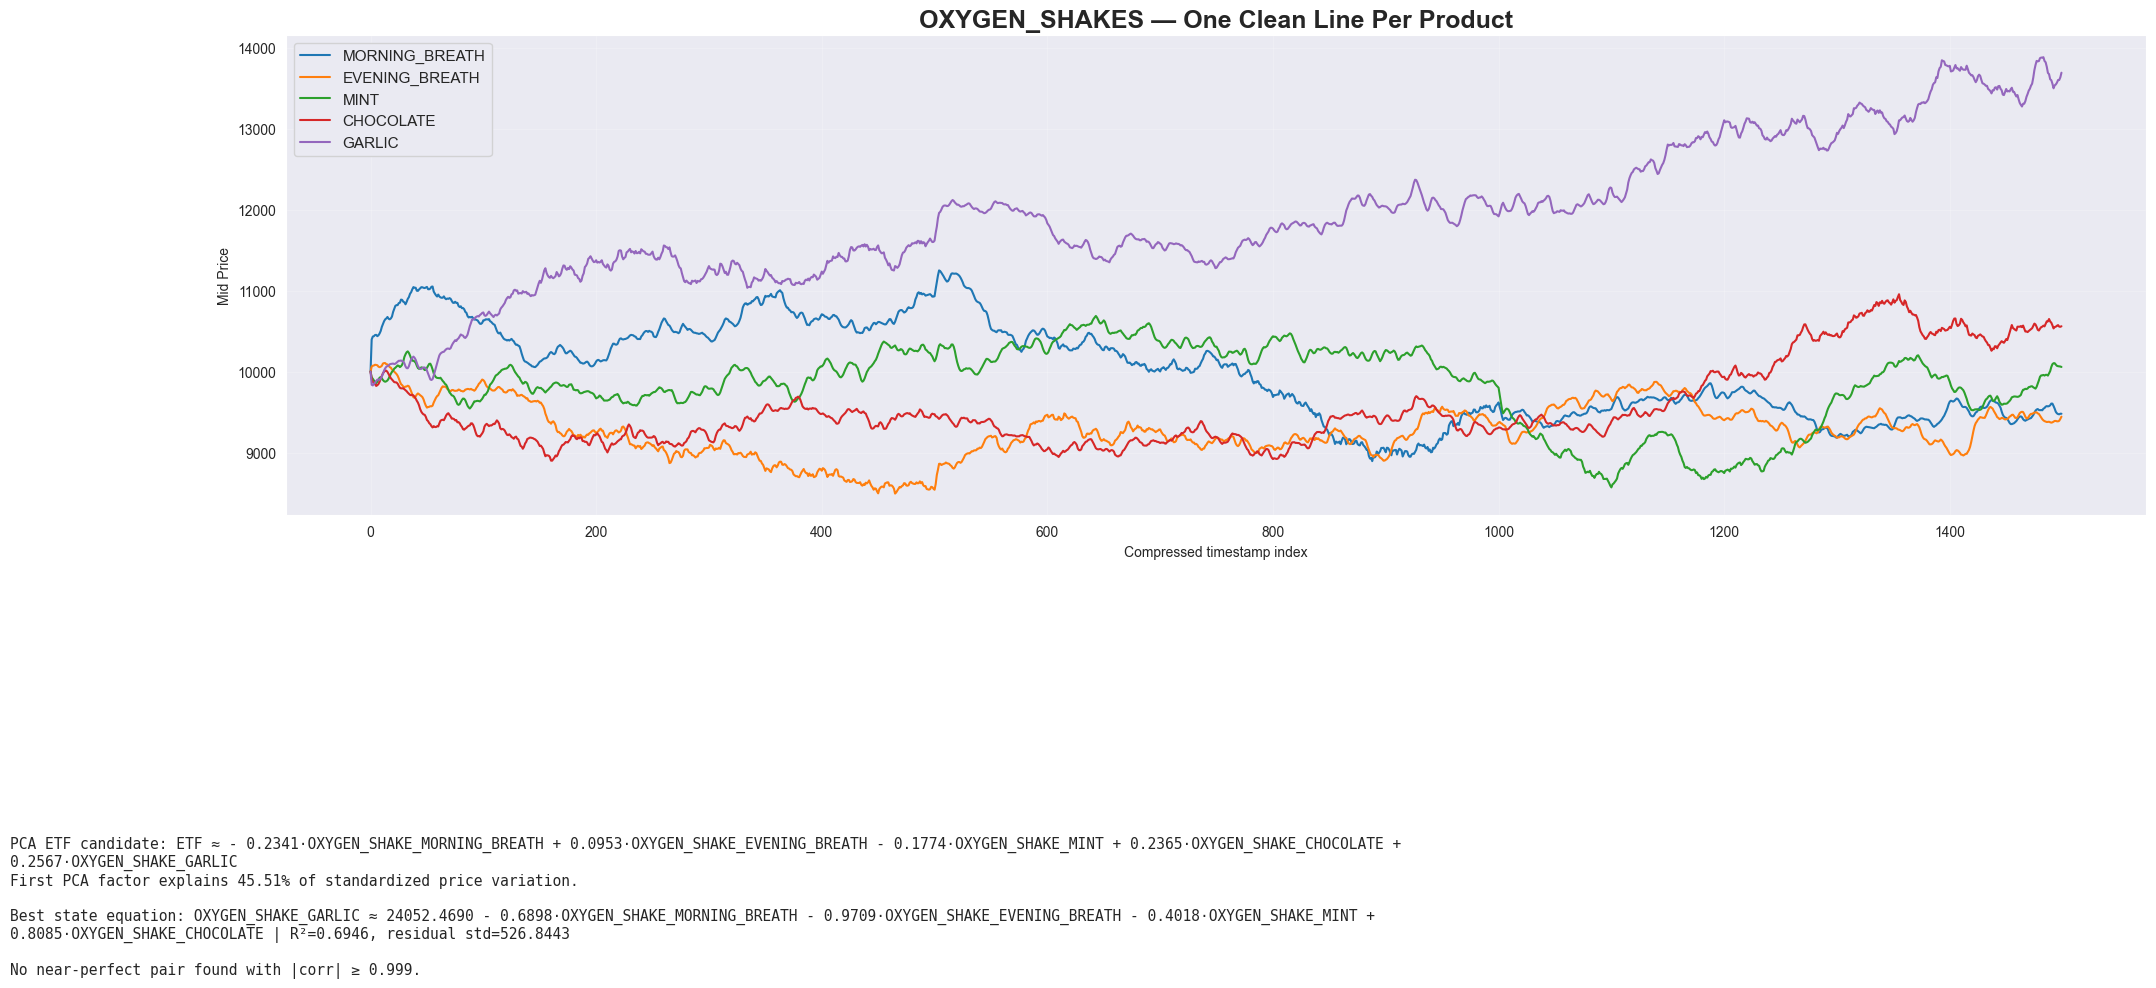

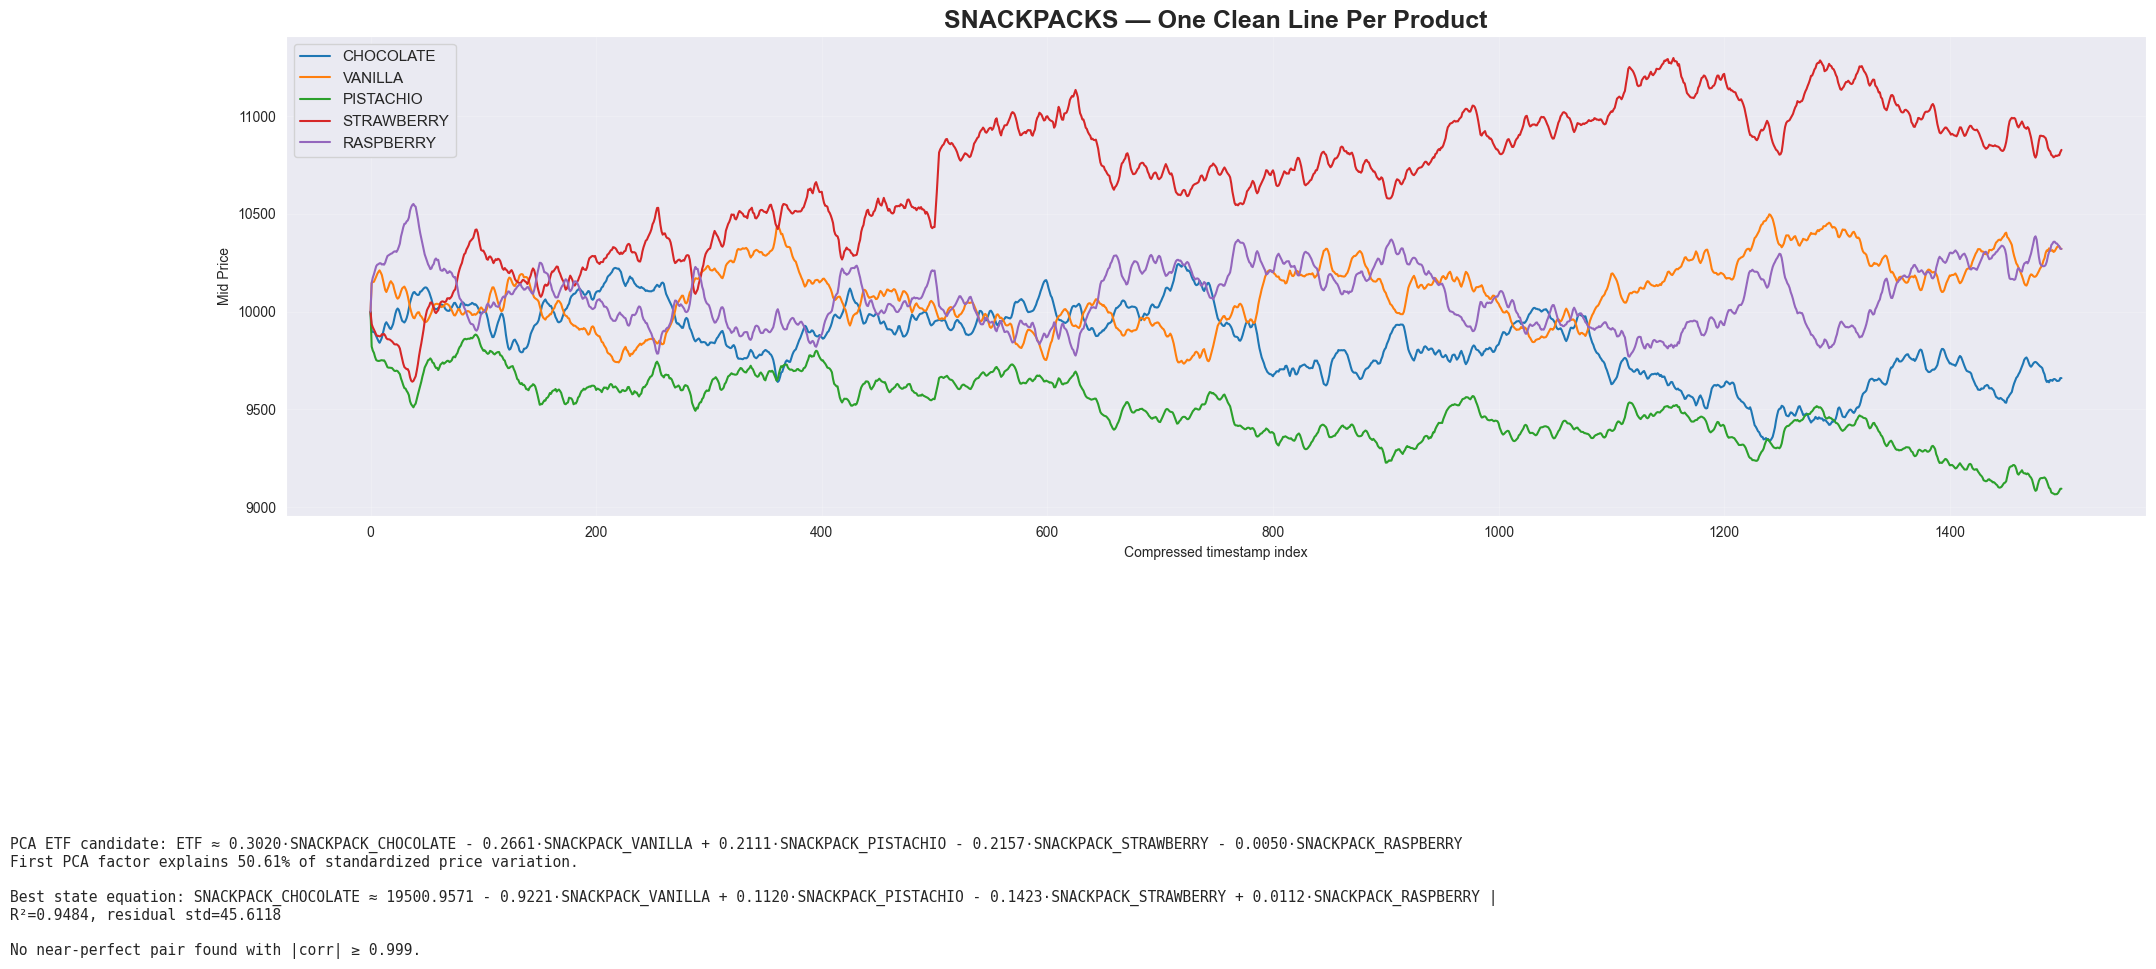

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import textwrap
from itertools import combinations

# ============================================================
# Official product groups
# ============================================================

GROUPS = {
    "GALAXY_SOUNDS_RECORDERS": [
        "GALAXY_SOUNDS_DARK_MATTER",
        "GALAXY_SOUNDS_BLACK_HOLES",
        "GALAXY_SOUNDS_PLANETARY_RINGS",
        "GALAXY_SOUNDS_SOLAR_WINDS",
        "GALAXY_SOUNDS_SOLAR_FLAMES",
    ],
    "SLEEP_PODS": [
        "SLEEP_POD_SUEDE",
        "SLEEP_POD_LAMB_WOOL",
        "SLEEP_POD_POLYESTER",
        "SLEEP_POD_NYLON",
        "SLEEP_POD_COTTON",
    ],
    "MICROCHIPS": [
        "MICROCHIP_CIRCLE",
        "MICROCHIP_OVAL",
        "MICROCHIP_SQUARE",
        "MICROCHIP_RECTANGLE",
        "MICROCHIP_TRIANGLE",
    ],
    "PEBBLES": [
        "PEBBLES_XS",
        "PEBBLES_S",
        "PEBBLES_M",
        "PEBBLES_L",
        "PEBBLES_XL",
    ],
    "ROBOTS": [
        "ROBOT_VACUUMING",
        "ROBOT_MOPPING",
        "ROBOT_DISHES",
        "ROBOT_LAUNDRY",
        "ROBOT_IRONING",
    ],
    "UV_VISORS": [
        "UV_VISOR_YELLOW",
        "UV_VISOR_AMBER",
        "UV_VISOR_ORANGE",
        "UV_VISOR_RED",
        "UV_VISOR_MAGENTA",
    ],
    "TRANSLATORS": [
        "TRANSLATOR_SPACE_GRAY",
        "TRANSLATOR_ASTRO_BLACK",
        "TRANSLATOR_ECLIPSE_CHARCOAL",
        "TRANSLATOR_GRAPHITE_MIST",
        "TRANSLATOR_VOID_BLUE",
    ],
    "PANELS": [
        "PANEL_1X2",
        "PANEL_2X2",
        "PANEL_1X4",
        "PANEL_2X4",
        "PANEL_4X4",
    ],
    "OXYGEN_SHAKES": [
        "OXYGEN_SHAKE_MORNING_BREATH",
        "OXYGEN_SHAKE_EVENING_BREATH",
        "OXYGEN_SHAKE_MINT",
        "OXYGEN_SHAKE_CHOCOLATE",
        "OXYGEN_SHAKE_GARLIC",
    ],
    "SNACKPACKS": [
        "SNACKPACK_CHOCOLATE",
        "SNACKPACK_VANILLA",
        "SNACKPACK_PISTACHIO",
        "SNACKPACK_STRAWBERRY",
        "SNACKPACK_RASPBERRY",
    ],
}

# ============================================================
# Settings
# ============================================================

LINEWIDTH = 1.5
SMOOTH_WINDOW = 75      # increase if still too noisy
DOWNSAMPLE = 20         # increase if still too dense
PERFECT_CORR_THRESHOLD = 0.999

# ============================================================
# Helpers
# ============================================================

def short_name(product, sector):
    prefixes = {
        "GALAXY_SOUNDS_RECORDERS": "GALAXY_SOUNDS_",
        "SLEEP_PODS": "SLEEP_POD_",
        "MICROCHIPS": "MICROCHIP_",
        "PEBBLES": "PEBBLES_",
        "ROBOTS": "ROBOT_",
        "UV_VISORS": "UV_VISOR_",
        "TRANSLATORS": "TRANSLATOR_",
        "PANELS": "PANEL_",
        "OXYGEN_SHAKES": "OXYGEN_SHAKE_",
        "SNACKPACKS": "SNACKPACK_",
    }
    return product.replace(prefixes.get(sector, ""), "")

def fmt(x):
    if abs(x) < 1e-4:
        return "0"
    return f"{x:.4f}"

def clean_series(s):
    s = pd.to_numeric(s, errors="coerce").copy()
    s = s.replace([np.inf, -np.inf], np.nan)
    s[s <= 0] = np.nan
    s = s.ffill().bfill()
    return s

def smooth_and_downsample(s, smooth_window=75, downsample=20):
    s = clean_series(s)
    s = s.rolling(smooth_window, min_periods=1).mean()
    return s.iloc[::downsample].reset_index(drop=True)

def pca_etf_equation(df_sector):
    X = df_sector.dropna().copy()
    X_std = (X - X.mean()) / X.std(ddof=0)
    X_std = X_std.replace([np.inf, -np.inf], np.nan).dropna()

    U, S, Vt = np.linalg.svd(X_std.values, full_matrices=False)
    weights = Vt[0]

    if weights[np.argmax(np.abs(weights))] < 0:
        weights = -weights

    weights = weights / np.sum(np.abs(weights))
    explained = (S[0] ** 2) / np.sum(S ** 2)

    terms = []
    for p, w in zip(X_std.columns, weights):
        sign = "+" if w >= 0 else "-"
        terms.append(f"{sign} {fmt(abs(w))}·{p}")

    eq = "ETF ≈ " + " ".join(terms)
    eq = eq.replace("≈ +", "≈")
    return eq, explained, weights

def best_state_equation(df_sector):
    Xall = df_sector.dropna().copy()
    best = None

    for target in Xall.columns:
        others = [c for c in Xall.columns if c != target]

        y = Xall[target].values
        X = Xall[others].values
        X_design = np.column_stack([np.ones(len(X)), X])

        coef, *_ = np.linalg.lstsq(X_design, y, rcond=None)
        y_hat = X_design @ coef
        resid = y - y_hat

        ss_res = np.sum(resid ** 2)
        ss_tot = np.sum((y - y.mean()) ** 2)
        r2 = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan
        resid_std = np.std(resid)

        if best is None or r2 > best["r2"]:
            best = {
                "target": target,
                "others": others,
                "coef": coef,
                "r2": r2,
                "resid_std": resid_std,
            }

    intercept = best["coef"][0]
    betas = best["coef"][1:]

    terms = [fmt(intercept)]
    for beta, name in zip(betas, best["others"]):
        sign = "+" if beta >= 0 else "-"
        terms.append(f"{sign} {fmt(abs(beta))}·{name}")

    eq = f"{best['target']} ≈ " + " ".join(terms)
    eq = eq.replace("≈ +", "≈")
    return eq, best

def near_perfect_pair_equations(df_sector, threshold=0.999):
    Xall = df_sector.dropna().copy()
    corr = Xall.corr()
    equations = []

    for i, a in enumerate(Xall.columns):
        for b in Xall.columns[i+1:]:
            rho = corr.loc[a, b]
            if abs(rho) >= threshold:
                x = Xall[a].values
                y = Xall[b].values
                X_design = np.column_stack([np.ones(len(x)), x])
                coef, *_ = np.linalg.lstsq(X_design, y, rcond=None)
                intercept, beta = coef

                eq = (
                    f"{b} ≈ {fmt(intercept)} "
                    f"{'+' if beta >= 0 else '-'} {fmt(abs(beta))}·{a} "
                    f"(corr={rho:.5f})"
                )
                equations.append(eq)

    return equations

# ============================================================
# Main loop
# ============================================================

for sector, members in GROUPS.items():

    members = [m for m in members if m in mid.columns]
    if not members:
        print(f"Skipping {sector}: no products found.")
        continue

    # raw data for equations
    df_sector_raw = pd.DataFrame(index=mid.index)
    for product in members:
        df_sector_raw[product] = clean_series(mid[product])

    # smoothed/downsampled data ONLY for plotting
    df_plot = pd.DataFrame()
    for product in members:
        df_plot[product] = smooth_and_downsample(
            mid[product],
            smooth_window=SMOOTH_WINDOW,
            downsample=DOWNSAMPLE
        )

    # equations
    etf_eq, explained, _ = pca_etf_equation(df_sector_raw)
    state_eq, state_info = best_state_equation(df_sector_raw)
    pair_eqs = near_perfect_pair_equations(df_sector_raw, threshold=PERFECT_CORR_THRESHOLD)

    # plot
    fig, ax = plt.subplots(figsize=(24, 8))

    x = np.arange(len(df_plot))

    for product in members:
        ax.plot(
            x,
            df_plot[product].values,
            linewidth=LINEWIDTH,
            linestyle="-",
            marker=None,
            alpha=1.0,
            label=short_name(product, sector)
        )

    ax.set_title(f"{sector} — One Clean Line Per Product", fontsize=18, fontweight="bold")
    ax.set_xlabel("Compressed timestamp index")
    ax.set_ylabel("Mid Price")
    ax.grid(True, alpha=0.2)
    ax.legend(fontsize=11, loc="best", frameon=True)

    # text below
    text_lines = []
    text_lines.append(f"PCA ETF candidate: {etf_eq}")
    text_lines.append(f"First PCA factor explains {explained:.2%} of standardized price variation.")
    text_lines.append("")
    text_lines.append(
        f"Best state equation: {state_eq} | "
        f"R²={state_info['r2']:.4f}, residual std={state_info['resid_std']:.4f}"
    )
    text_lines.append("")

    if pair_eqs:
        text_lines.append(f"Near-perfect pair equations, |corr| ≥ {PERFECT_CORR_THRESHOLD}:")
        for eq in pair_eqs:
            text_lines.append(f"- {eq}")
    else:
        text_lines.append(f"No near-perfect pair found with |corr| ≥ {PERFECT_CORR_THRESHOLD}.")

    full_text = "\n".join(text_lines)

    wrapped_lines = []
    for line in full_text.split("\n"):
        if len(line) > 170:
            wrapped_lines.extend(textwrap.wrap(line, width=170, replace_whitespace=False))
        else:
            wrapped_lines.append(line)

    fig.text(
        0.01,
        -0.12,
        "\n".join(wrapped_lines),
        fontsize=10.5,
        family="monospace",
        va="top"
    )

    plt.subplots_adjust(bottom=0.28)
    plt.show()
    

---
## 4. Raw Price Evolution — All 10 Sectors

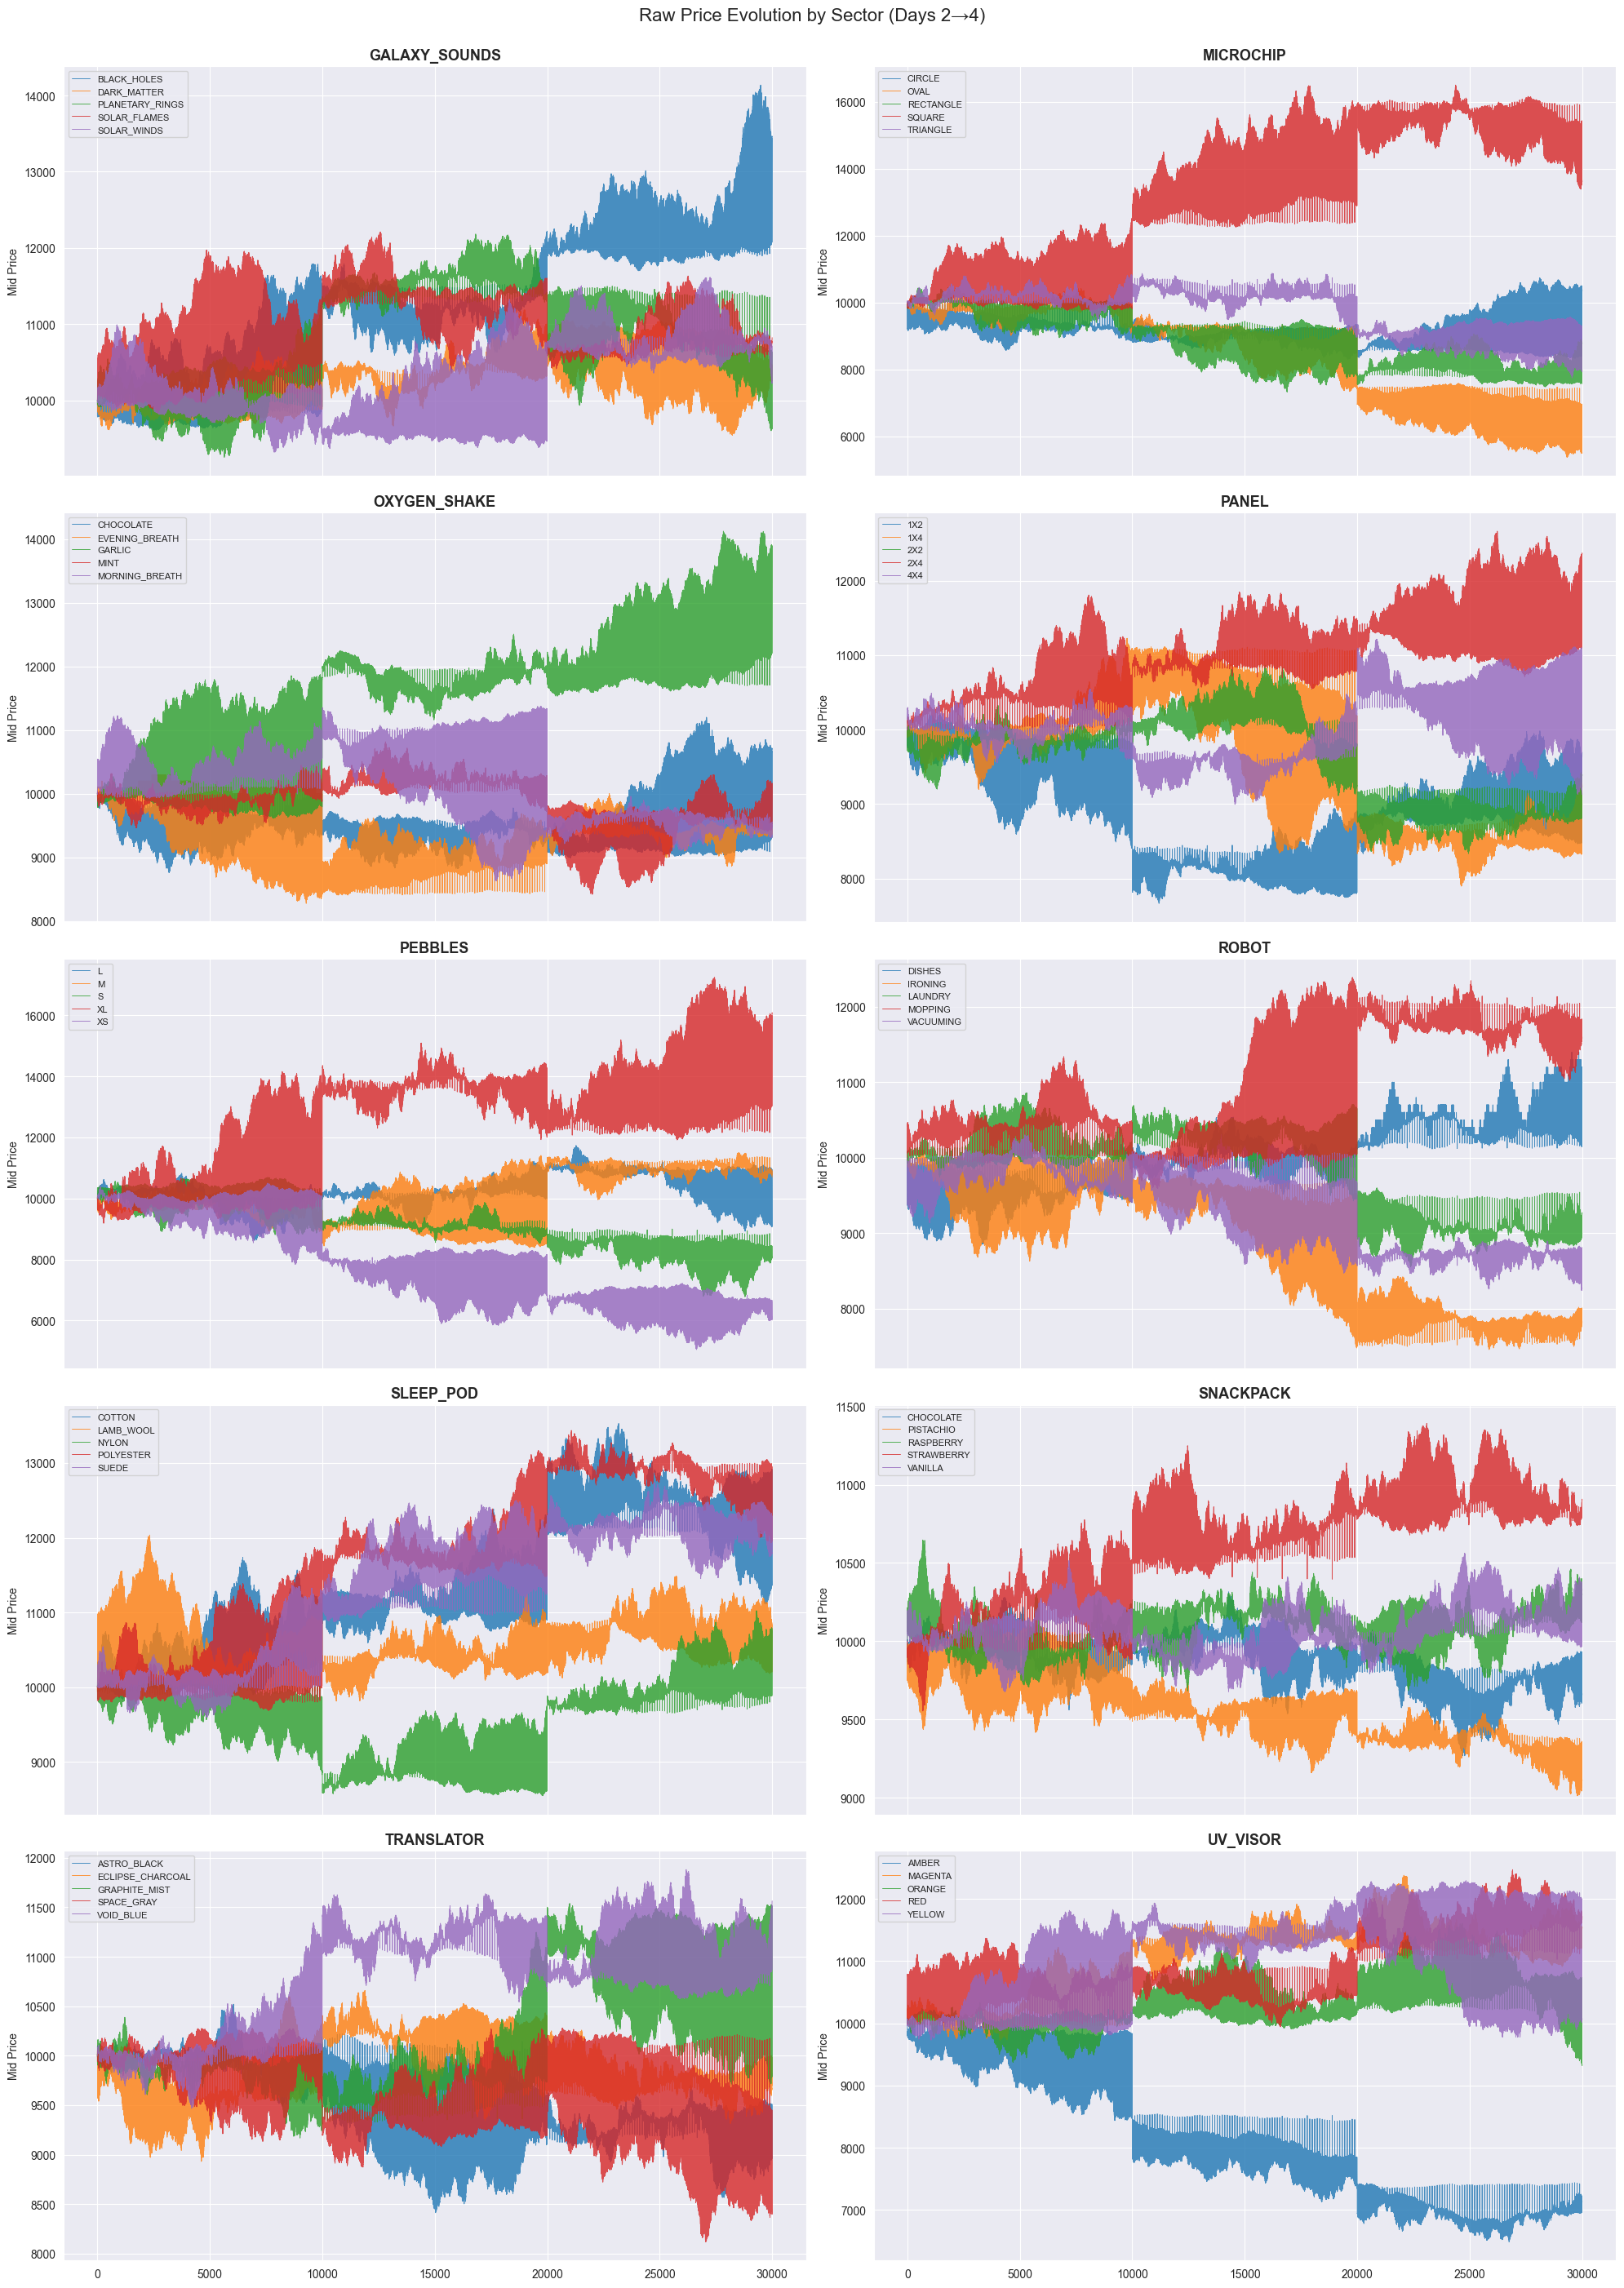

In [8]:
fig, axes = plt.subplots(5, 2, figsize=(20, 28), sharex=True)
axes = axes.flatten()

for i, sector in enumerate(sectors):
    ax = axes[i]
    members = sorted([p for p in products if sector_map[p] == sector])
    for m in members:
        label = m.replace(sector + '_', '')
        ax.plot(mid[m].values, label=label, alpha=0.8, linewidth=0.7)
    ax.set_title(sector, fontsize=13, fontweight='bold')
    ax.legend(fontsize=8, loc='best')
    ax.set_ylabel('Mid Price')

plt.suptitle('Raw Price Evolution by Sector (Days 2→4)', fontsize=16, y=1.0)
plt.tight_layout()
plt.show()

---
## 5. Normalised Prices (base = 100) — Divergence Detection

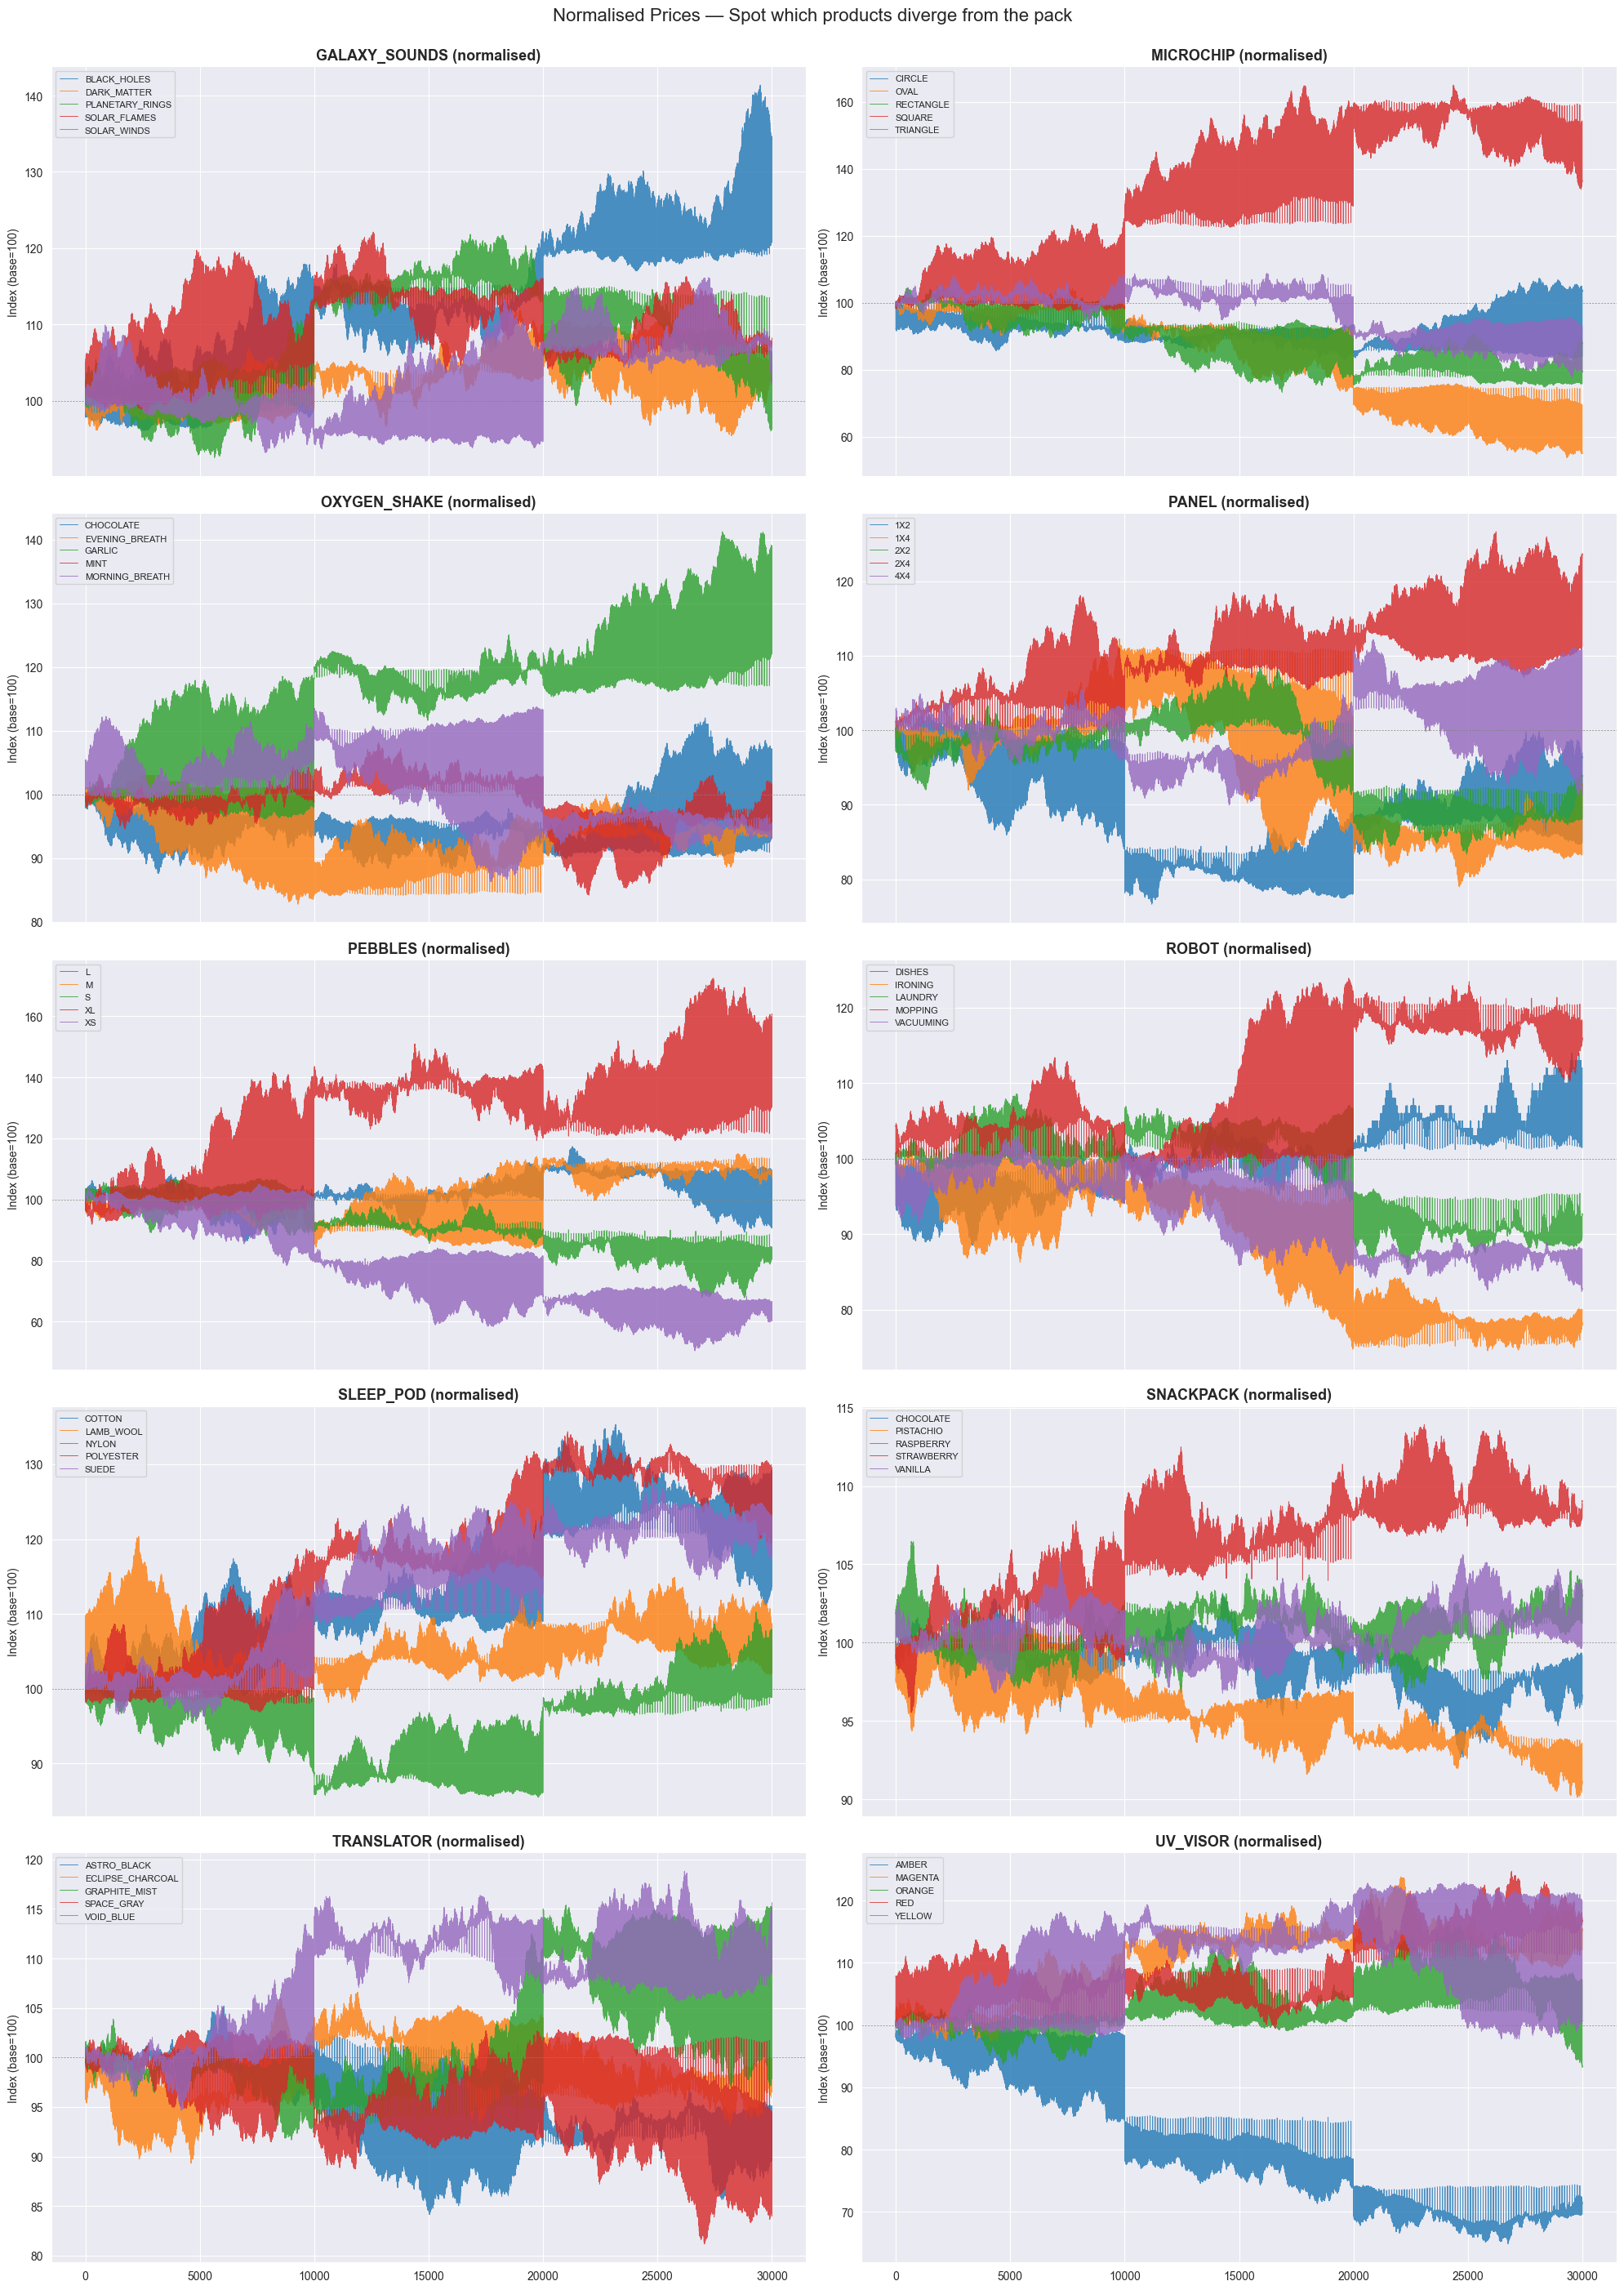

In [9]:
normed = mid / mid.iloc[0] * 100

fig, axes = plt.subplots(5, 2, figsize=(20, 28), sharex=True)
axes = axes.flatten()

for i, sector in enumerate(sectors):
    ax = axes[i]
    members = sorted([p for p in products if sector_map[p] == sector])
    for m in members:
        label = m.replace(sector + '_', '')
        ax.plot(normed[m].values, label=label, alpha=0.8, linewidth=0.7)
    ax.axhline(100, color='gray', ls='--', lw=0.5)
    ax.set_title(f'{sector} (normalised)', fontsize=13, fontweight='bold')
    ax.legend(fontsize=8, loc='best')
    ax.set_ylabel('Index (base=100)')

plt.suptitle('Normalised Prices — Spot which products diverge from the pack', fontsize=16, y=1.0)
plt.tight_layout()
plt.show()

---
## 6. Intra-Sector Return Correlations

**Critical finding**: Most sectors have **negative** average intra-sector correlation!  
This suggests a **zero-sum** or **rotation** dynamic within sectors — when one product goes up, others tend to go down.  
→ This is the opposite of what you'd see in equity sectors and has major implications for trading.


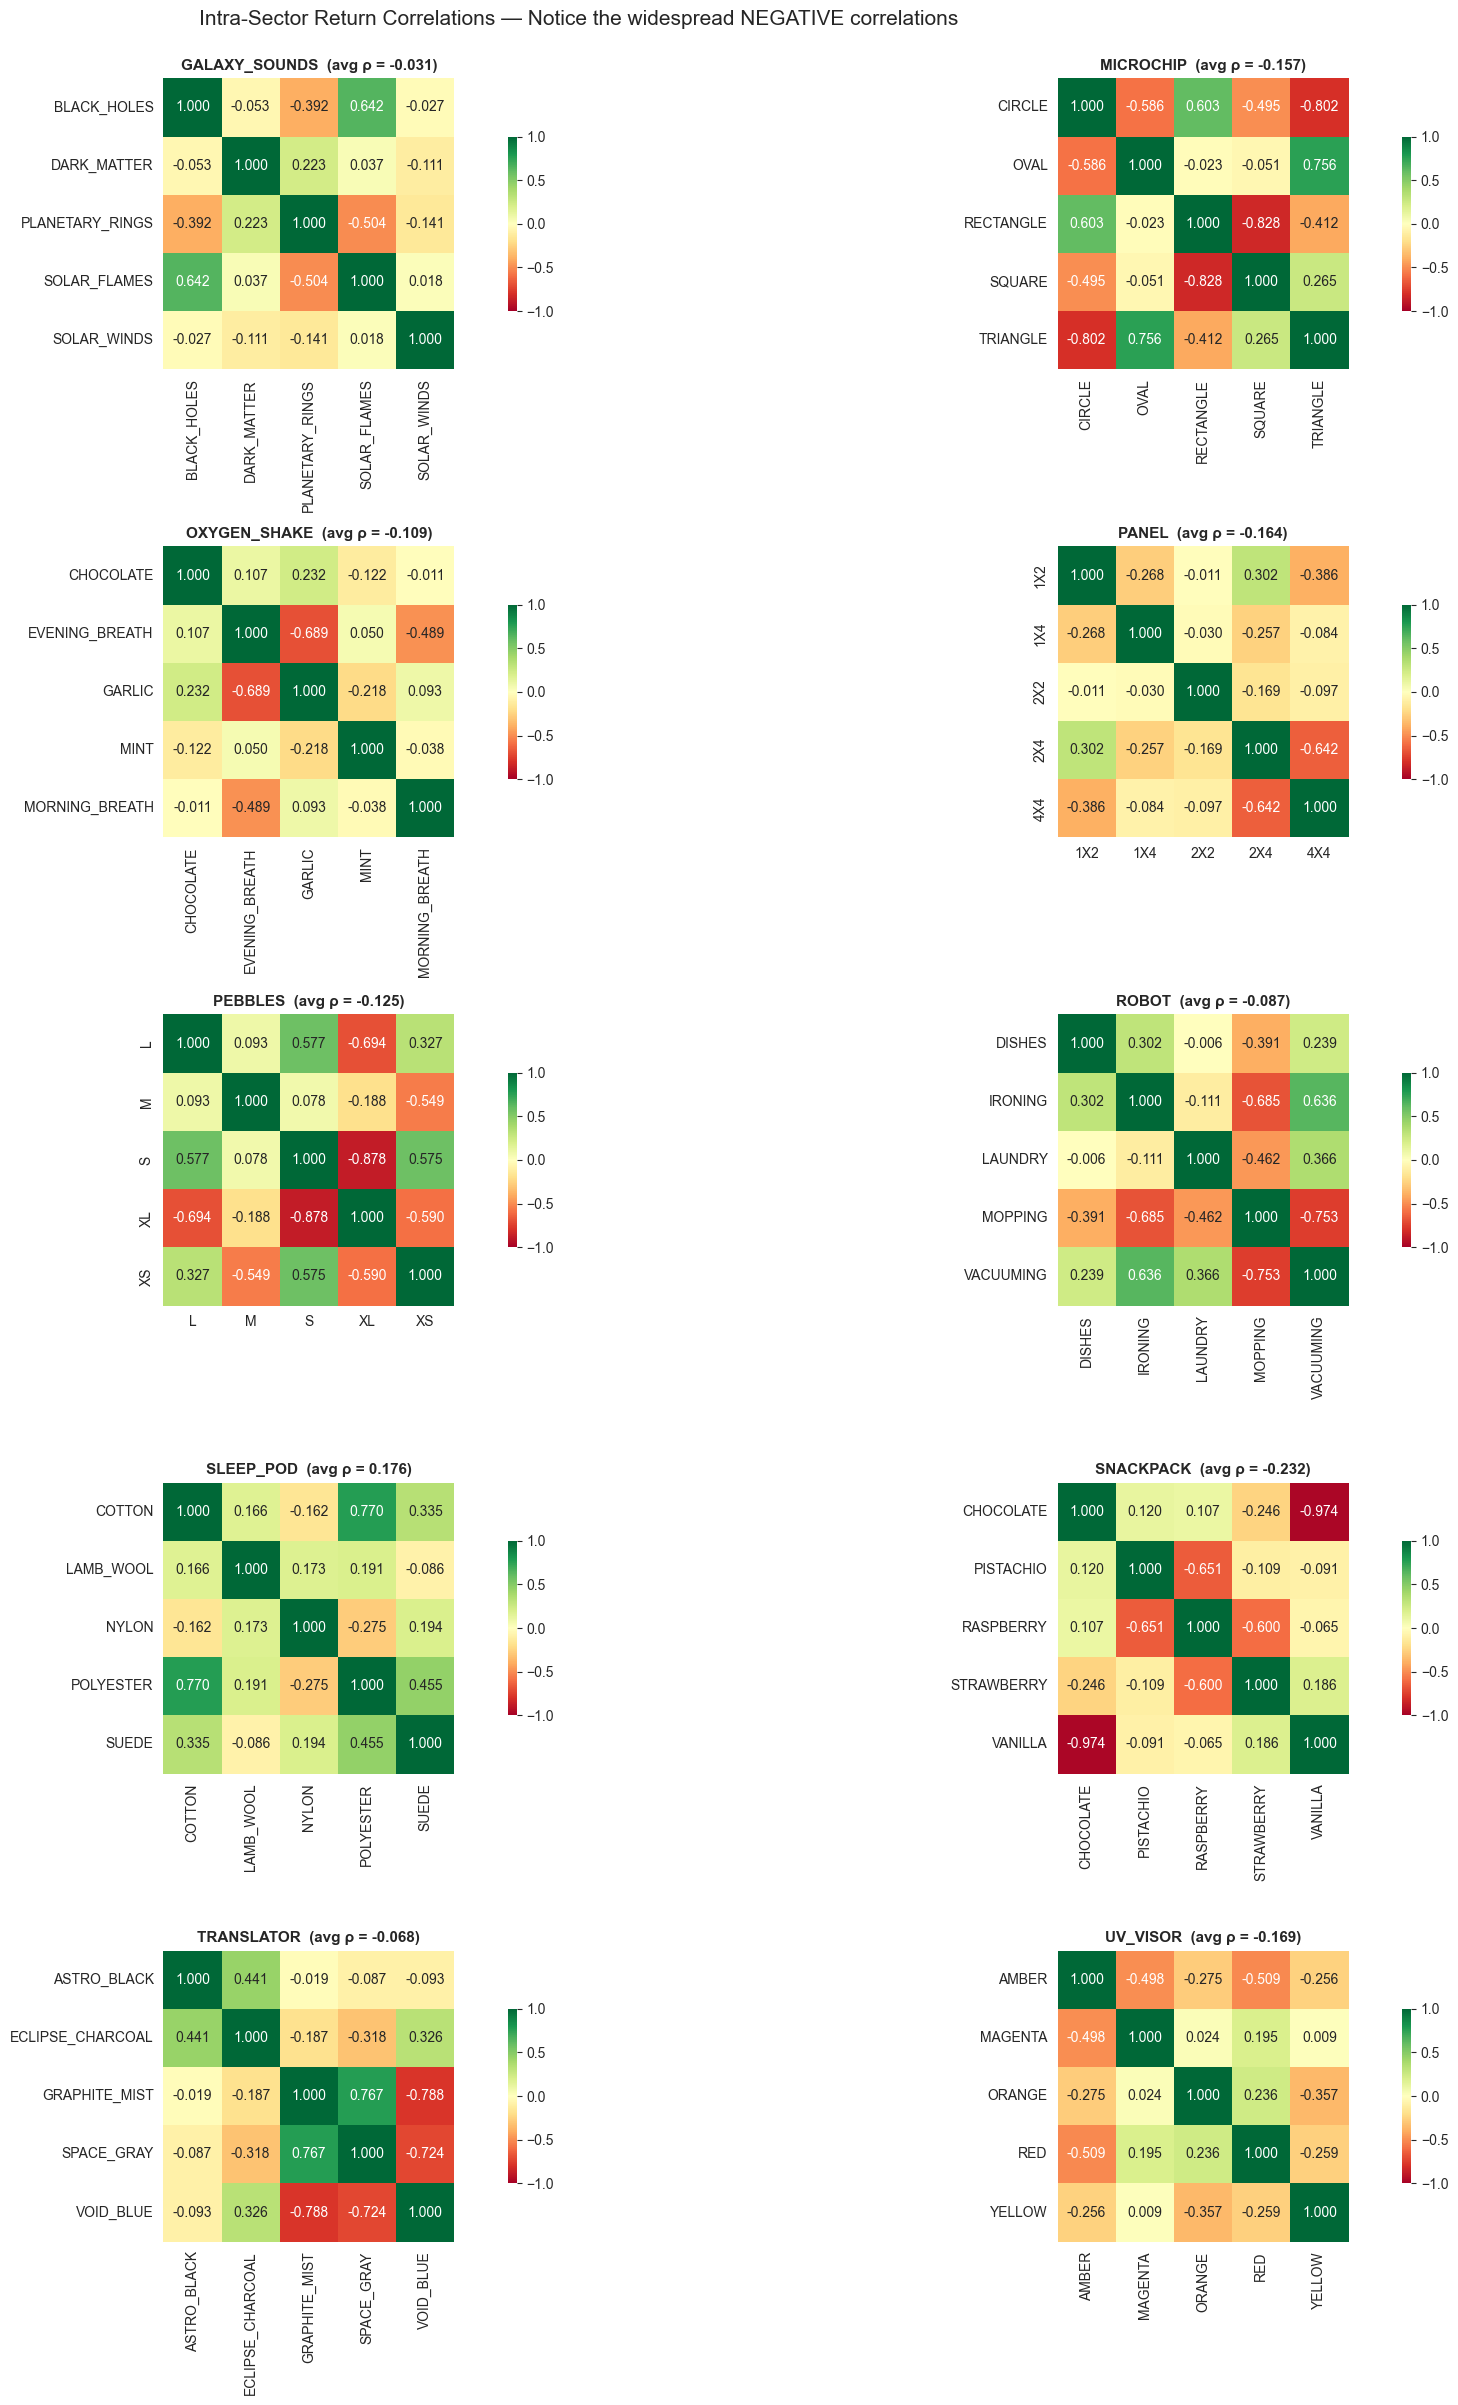


═══ Intra-Sector Correlation Summary ═══

               mean_corr  min_corr  max_corr  std_corr  n_negative  n_positive
SLEEP_POD       0.176138 -0.274734  0.769977  0.290295         3.0         7.0
GALAXY_SOUNDS  -0.030737 -0.504025  0.642124  0.299645         6.0         4.0
TRANSLATOR     -0.068124 -0.787535  0.766871  0.462693         7.0         3.0
ROBOT          -0.086511 -0.752782  0.636345  0.450183         6.0         4.0
OXYGEN_SHAKE   -0.108555 -0.689305  0.232363  0.271416         6.0         4.0
PEBBLES        -0.124906 -0.877743  0.576593  0.506641         5.0         5.0
MICROCHIP      -0.157322 -0.828344  0.755819  0.533627         7.0         3.0
PANEL          -0.164099 -0.641912  0.302109  0.238044         9.0         1.0
UV_VISOR       -0.169048 -0.508715  0.235760  0.255131         6.0         4.0
SNACKPACK      -0.232202 -0.973545  0.186190  0.365769         7.0         3.0

KEY TAKEAWAYS:
  • SLEEP_POD is the ONLY sector with positive avg correlation (+0.18)
 

In [10]:
fig, axes = plt.subplots(5, 2, figsize=(20, 24))
axes = axes.flatten()

intra_corr_summary = {}
colors_sec = plt.cm.tab10(np.linspace(0, 1, len(sectors)))
sector_color = {s: colors_sec[i] for i, s in enumerate(sectors)}

for i, sector in enumerate(sectors):
    ax = axes[i]
    members = sorted([p for p in products if sector_map[p] == sector])
    short_names = [m.replace(sector + '_', '') for m in members]
    corr = returns[members].corr()
    corr.index = short_names
    corr.columns = short_names
    
    mask_ut = np.triu(np.ones_like(corr, dtype=bool), k=1)
    ut_vals = corr.values[mask_ut]
    intra_corr_summary[sector] = {
        'mean_corr': ut_vals.mean(), 'min_corr': ut_vals.min(),
        'max_corr': ut_vals.max(), 'std_corr': ut_vals.std(),
        'n_negative': (ut_vals < 0).sum(), 'n_positive': (ut_vals > 0).sum()
    }
    
    sns.heatmap(corr, annot=True, fmt='.3f', cmap='RdYlGn', center=0,
                vmin=-1, vmax=1, ax=ax, square=True, cbar_kws={'shrink': 0.6})
    ax.set_title(f'{sector}  (avg ρ = {ut_vals.mean():.3f})', fontsize=11, fontweight='bold')

plt.suptitle('Intra-Sector Return Correlations — Notice the widespread NEGATIVE correlations', fontsize=15, y=1.0)
plt.tight_layout()
plt.show()

ic_df = pd.DataFrame(intra_corr_summary).T.sort_values('mean_corr', ascending=False)
print("\n═══ Intra-Sector Correlation Summary ═══\n")
print(ic_df.to_string())
print()
print("KEY TAKEAWAYS:")
print("  • SLEEP_POD is the ONLY sector with positive avg correlation (+0.18)")
print("  • SNACKPACK has extreme anti-correlation (min = -0.97!) → pairs gold mine")
print("  • Negative avg correlations suggest a rotation/zero-sum game within sectors")
print("  • This means a LONG-SHORT spread strategy is natural, not a long-only ETF")

---
## 7. Full 50×50 Correlation Matrix — Cross-Sector Structure

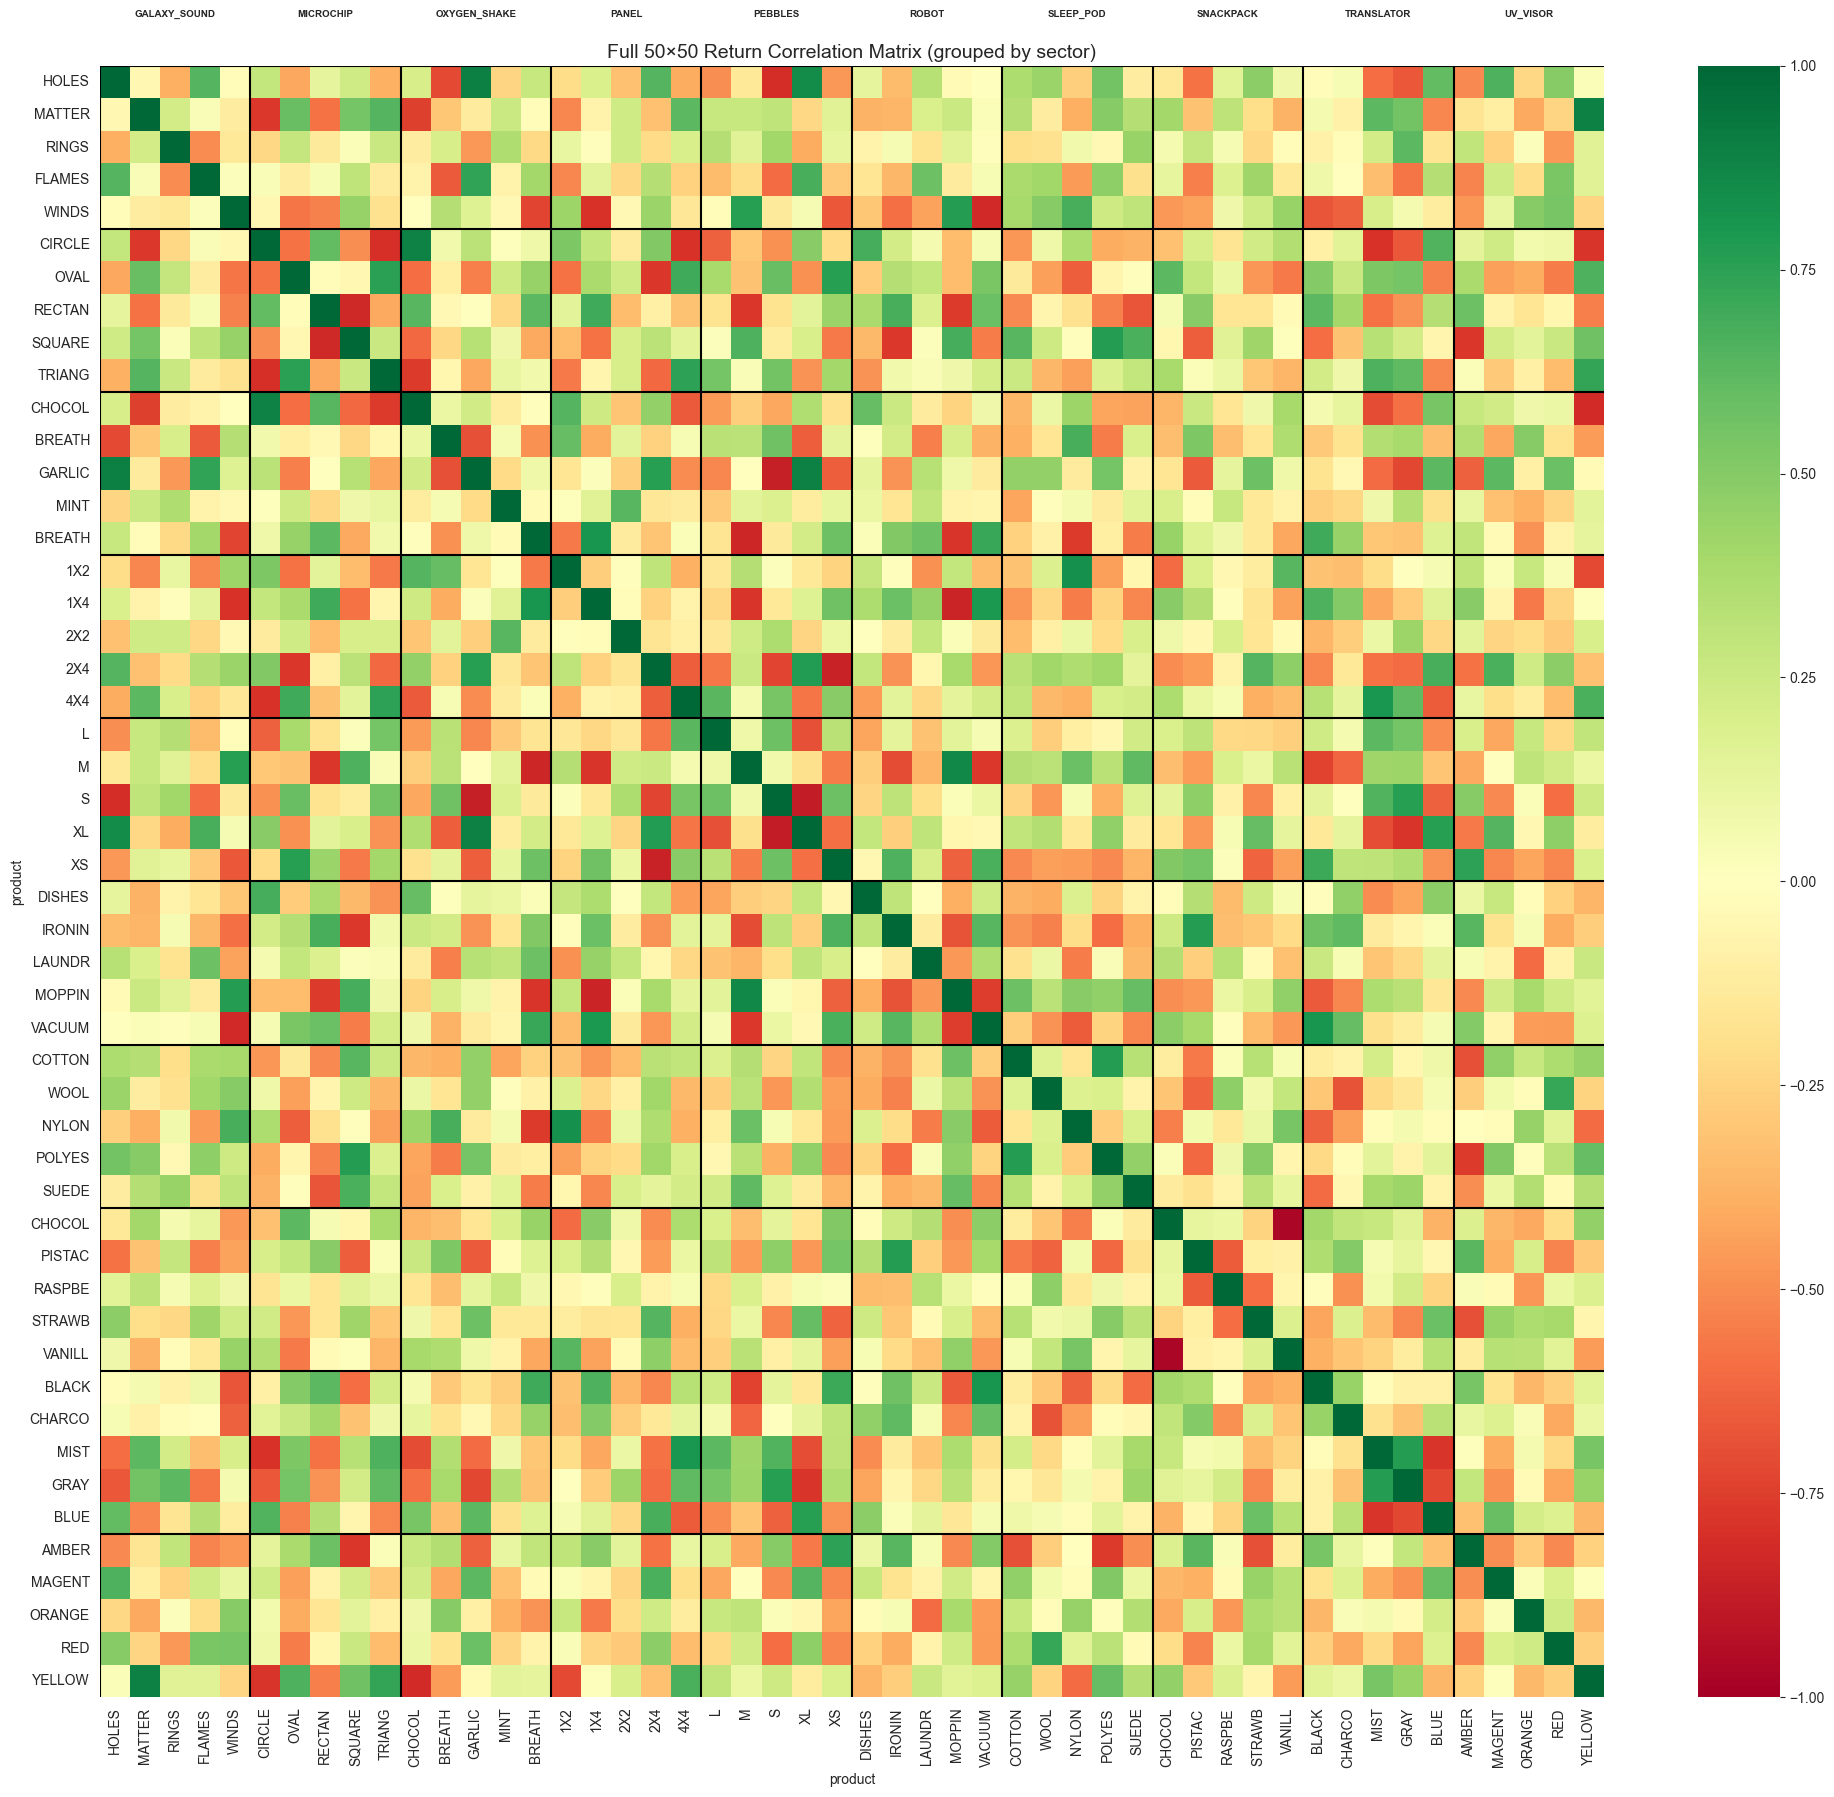

In [11]:
corr_full = returns.corr()

ordered = []
for s in sectors:
    ordered += sorted([p for p in products if sector_map[p] == s])
corr_ordered = corr_full.loc[ordered, ordered]

fig, ax = plt.subplots(figsize=(20, 18))
sns.heatmap(corr_ordered, cmap='RdYlGn', center=0, vmin=-1, vmax=1,
            xticklabels=[p.split('_')[-1][:6] for p in ordered],
            yticklabels=[p.split('_')[-1][:6] for p in ordered], ax=ax)

# Sector dividers
cum = 0
for s in sectors:
    n = sum(1 for p in products if sector_map[p] == s)
    ax.axhline(cum, color='black', lw=1.5)
    ax.axvline(cum, color='black', lw=1.5)
    ax.text(cum + n/2, -1.5, s[:12], ha='center', fontsize=7, fontweight='bold')
    cum += n

ax.set_title('Full 50×50 Return Correlation Matrix (grouped by sector)', fontsize=14)
plt.tight_layout()
plt.show()

---
## 10. Sector ETFs — Equal-Weight Baskets

Even though intra-correlations are mostly negative, the equal-weight basket represents  
the **sector average price level**. Spreads against this basket reveal relative value.


═══ ETF (equal-weight basket) Statistics ═══

                   mean_ret   std_ret  sharpe_proxy  range_pct
PEBBLES        3.421188e-09  0.000079      0.000044   0.070000
SNACKPACK      1.796069e-06  0.001786      0.001005   1.830910
ROBOT          2.041197e-05  0.006585      0.003100   8.101884
UV_VISOR       2.833630e-05  0.007545      0.003756   8.088089
PANEL          3.049888e-05  0.007830      0.003895   9.205563
MICROCHIP      4.742056e-05  0.010006      0.004739  12.950315
TRANSLATOR     5.647276e-05  0.010729      0.005263   8.303734
GALAXY_SOUNDS  7.991090e-05  0.012420      0.006434  13.436667
OXYGEN_SHAKE   8.704111e-05  0.013023      0.006684   9.622823
SLEEP_POD      1.263465e-04  0.015642      0.008078  18.555987

Note: Because intra-sector correlations are negative,
the ETF has MUCH LOWER vol than individual products (diversification benefit).


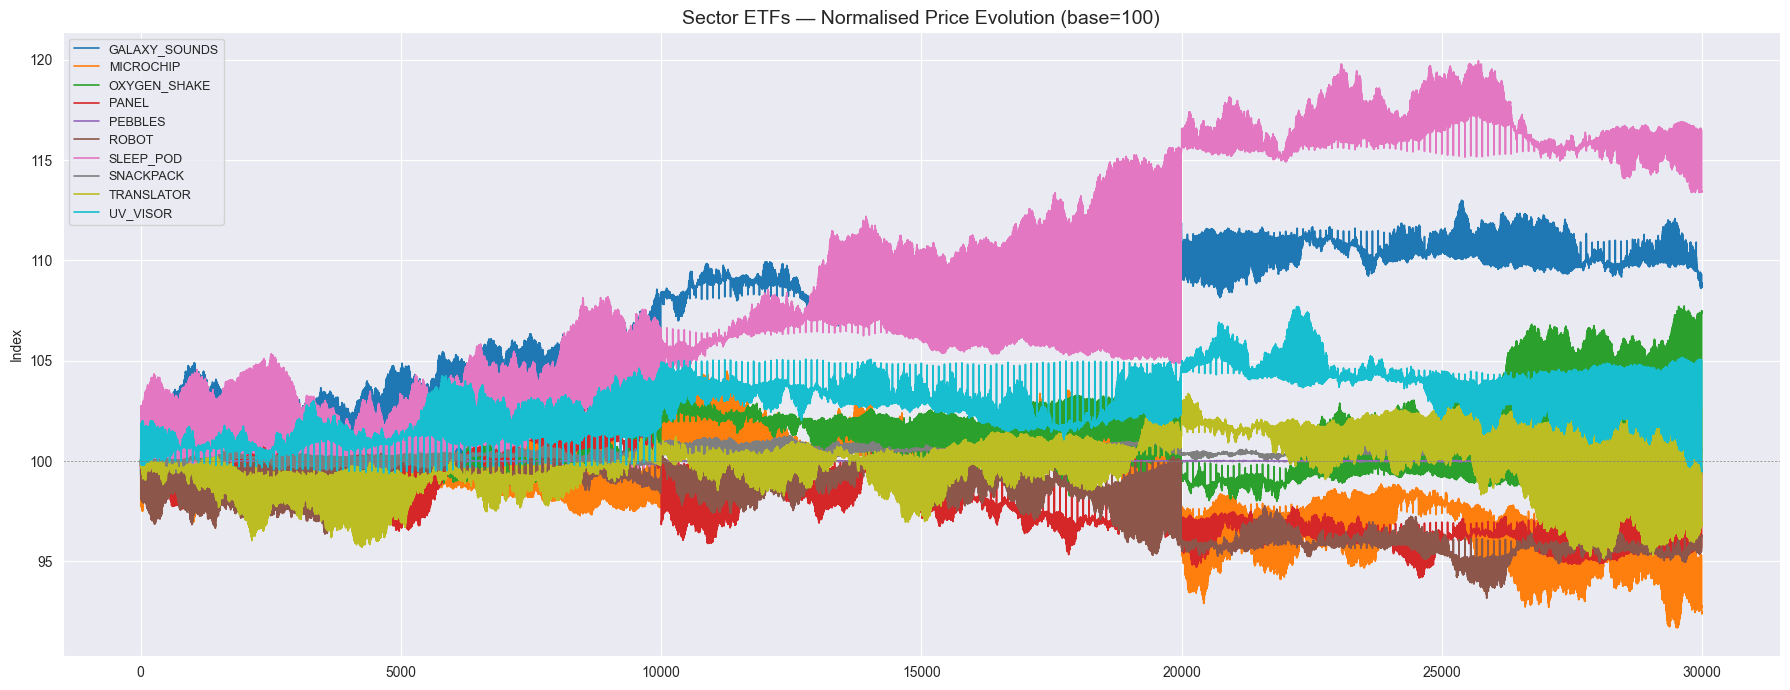

In [14]:
etf_prices = pd.DataFrame()
for s in sectors:
    members = [p for p in products if sector_map[p] == s]
    etf_prices[s] = mid[members].mean(axis=1)

etf_returns = etf_prices.pct_change().dropna()

etf_desc = pd.DataFrame({
    'mean_ret': etf_returns.mean(),
    'std_ret': etf_returns.std(),
    'sharpe_proxy': etf_returns.mean() / etf_returns.std(),
    'range_pct': (etf_prices.max() - etf_prices.min()) / etf_prices.mean() * 100
}).sort_values('std_ret')

print("═══ ETF (equal-weight basket) Statistics ═══\n")
print(etf_desc.to_string())
print()
print("Note: Because intra-sector correlations are negative,")
print("the ETF has MUCH LOWER vol than individual products (diversification benefit).")

fig, ax = plt.subplots(figsize=(18, 7))
normed_etf = etf_prices / etf_prices.iloc[0] * 100
for s in sectors:
    ax.plot(normed_etf[s].values, label=s, linewidth=1.2)
ax.legend(fontsize=9)
ax.set_title('Sector ETFs — Normalised Price Evolution (base=100)', fontsize=14)
ax.set_ylabel('Index')
ax.axhline(100, color='gray', ls='--', lw=0.5)
plt.tight_layout()
plt.show()

---
## 11. Product vs Sector-ETF — Spread Analysis

Compute spread = `product_price − sector_ETF` for each product.  
Products with **low spread volatility** are **anchors** (track the basket closely).  
Products with **high spread volatility** are prime **spread-trade** candidates.


In [15]:
spreads = pd.DataFrame()
residual_stats = []

for p in products:
    s = sector_map[p]
    spread = mid[p] - etf_prices[s]
    spreads[p] = spread
    residual_stats.append({
        'product': p, 'sector': s,
        'spread_mean': spread.mean(),
        'spread_std': spread.std(),
        'spread_range': spread.max() - spread.min(),
        'spread_zscore_max': abs(spread - spread.mean()).max() / spread.std() if spread.std() > 0 else 0,
    })

res_df = pd.DataFrame(residual_stats).sort_values(['sector', 'spread_std'])

print("═══ Product Spread vs Sector ETF ═══\n")
print(res_df[['product', 'sector', 'spread_mean', 'spread_std', 'spread_range', 'spread_zscore_max']].to_string(index=False))

print("\n═══ Per-Sector: ANCHOR (most stable) vs OUTLIER (most volatile) ═══\n")
for s in sectors:
    sub = res_df[res_df['sector'] == s]
    anchor = sub.iloc[0]
    outlier = sub.iloc[-1]
    ratio = outlier['spread_std'] / anchor['spread_std']
    print(f"  {s:25s}  ANCHOR: {anchor['product'].replace(s+'_',''):15s} (σ={anchor['spread_std']:7.2f})   "
          f"OUTLIER: {outlier['product'].replace(s+'_',''):15s} (σ={outlier['spread_std']:7.2f})  ratio={ratio:.1f}x")

═══ Product Spread vs Sector ETF ═══

                      product        sector  spread_mean  spread_std  spread_range  spread_zscore_max
    GALAXY_SOUNDS_DARK_MATTER GALAXY_SOUNDS  -571.402733  365.188725        1551.5           2.370000
    GALAXY_SOUNDS_SOLAR_WINDS GALAXY_SOUNDS  -360.520583  454.592387        2022.8           2.388908
   GALAXY_SOUNDS_SOLAR_FLAMES GALAXY_SOUNDS   294.507150  534.130262        2102.9           2.270781
GALAXY_SOUNDS_PLANETARY_RINGS GALAXY_SOUNDS   -31.391367  617.319585        2475.6           2.087911
    GALAXY_SOUNDS_BLACK_HOLES GALAXY_SOUNDS   668.807533  749.863651        3425.4           3.035875
           MICROCHIP_TRIANGLE     MICROCHIP  -195.221463  593.252426        2301.7           2.198016
          MICROCHIP_RECTANGLE     MICROCHIP -1149.173197  709.721353        3086.4           2.264090
             MICROCHIP_CIRCLE     MICROCHIP  -666.727263  719.325449        2987.5           2.674071
               MICROCHIP_OVAL     MICROCHIP 

---
## 12. Spread Time-Series — Visual Mean-Reversion Check

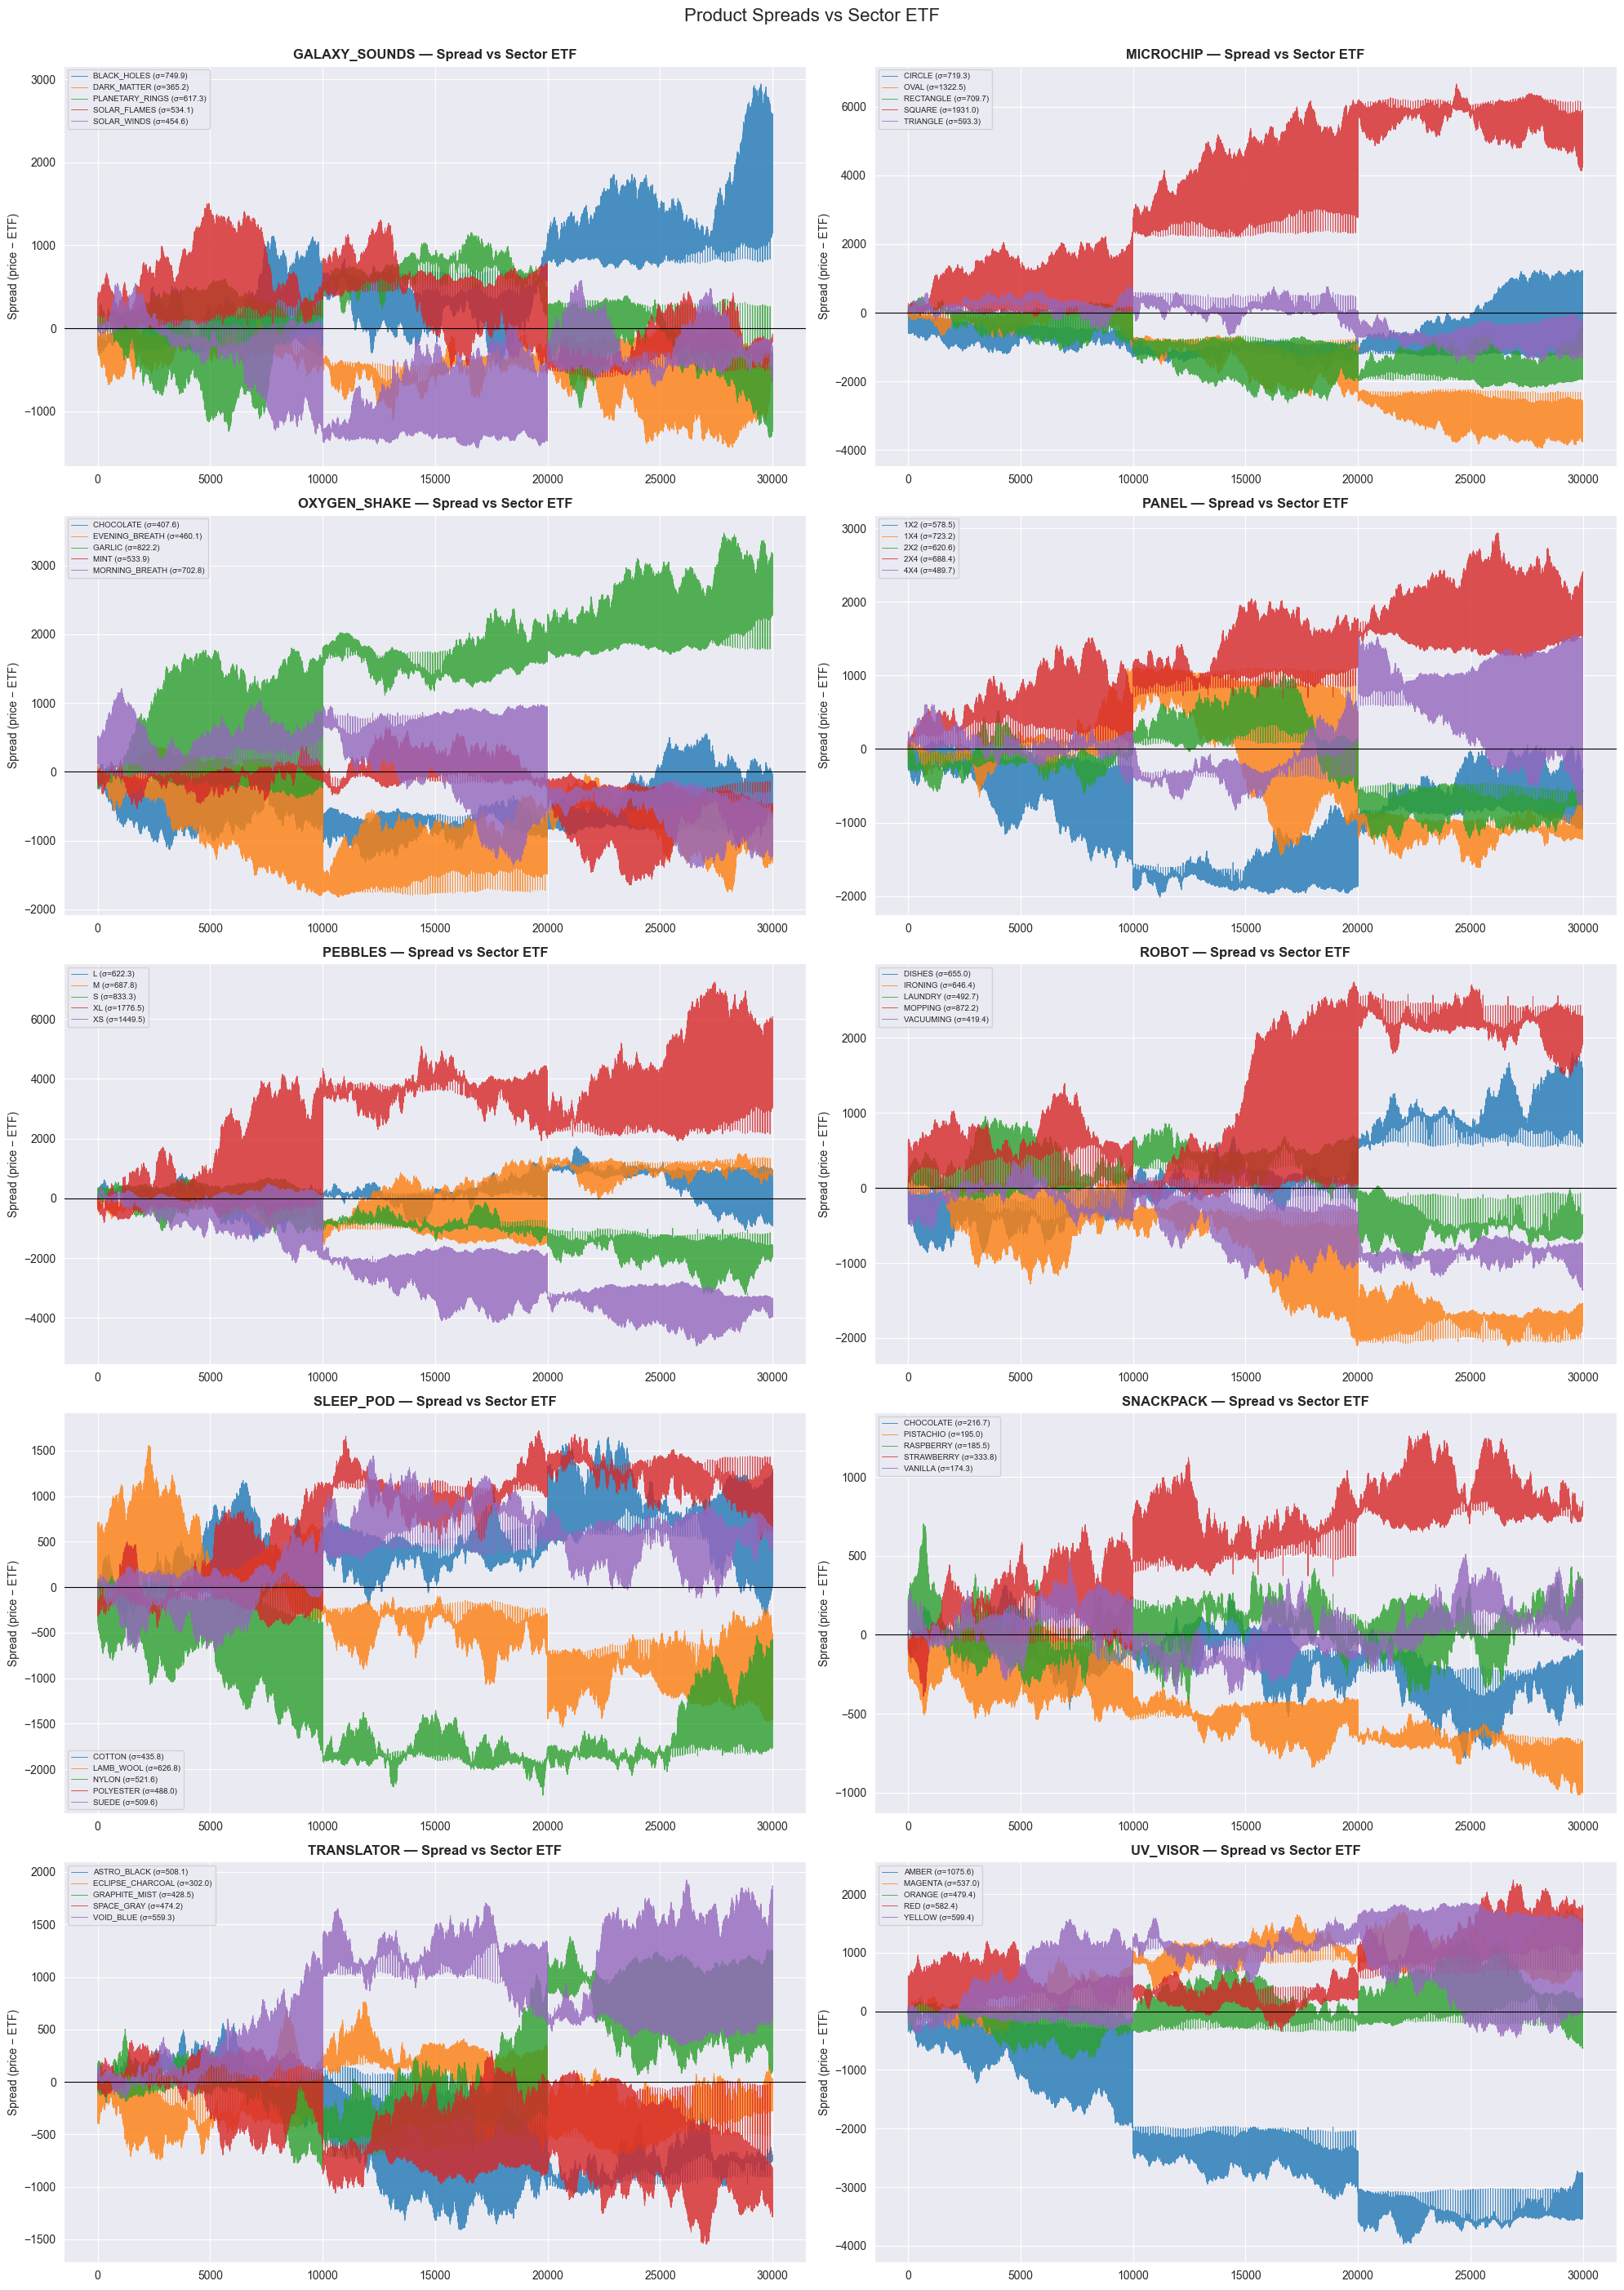

In [16]:
fig, axes = plt.subplots(5, 2, figsize=(20, 28))
axes = axes.flatten()

for i, sector in enumerate(sectors):
    ax = axes[i]
    members = sorted([p for p in products if sector_map[p] == sector])
    for m in members:
        label = m.replace(sector + '_', '')
        sp = spreads[m]
        ax.plot(sp.values, label=f'{label} (σ={sp.std():.1f})', alpha=0.8, linewidth=0.7)
    ax.axhline(0, color='black', ls='-', lw=0.8)
    ax.set_title(f'{sector} — Spread vs Sector ETF', fontsize=12, fontweight='bold')
    ax.legend(fontsize=7, loc='best')
    ax.set_ylabel('Spread (price − ETF)')

plt.suptitle('Product Spreads vs Sector ETF', fontsize=16, y=1.0)
plt.tight_layout()
plt.show()

---
## 13. Intra-Sector Pair Spreads — Half-Life & Mean-Reversion Strength

For every intra-sector pair:
1. Compute spread = P1 − P2
2. Fit AR(1): ΔS_t = β·S_{t-1} + ε → half-life = −ln(2)/β  
3. Rank by half-life (lower = faster reversion = more tradeable)


In [17]:
pair_results = []

for sector in sectors:
    members = sorted([p for p in products if sector_map[p] == sector])
    for p1, p2 in combinations(members, 2):
        spread = mid[p1] - mid[p2]
        spread_dm = spread - spread.mean()
        sl = spread_dm.shift(1).dropna()
        sd = spread_dm.diff().dropna()
        aligned = pd.DataFrame({'y': sd, 'x': sl}).dropna()
        
        if len(aligned) > 10 and aligned['x'].std() > 0:
            slope, intercept, r_val, p_val, std_err = stats.linregress(aligned['x'], aligned['y'])
            half_life = -np.log(2) / slope if slope < 0 else np.inf
        else:
            slope, p_val, half_life = 0, 1, np.inf
        
        corr_val = returns[p1].corr(returns[p2])
        
        pair_results.append({
            'sector': sector,
            'pair': f"{p1.replace(sector+'_','')} / {p2.replace(sector+'_','')}",
            'p1': p1, 'p2': p2,
            'spread_std': spread.std(),
            'spread_mean': spread.mean(),
            'spread_range': spread.max() - spread.min(),
            'ar1_slope': slope,
            'half_life': min(half_life, 99999),
            'return_corr': corr_val,
        })

pairs_df = pd.DataFrame(pair_results)
good_pairs = pairs_df[pairs_df['ar1_slope'] < 0].sort_values('half_life')

print("═══ ALL Intra-Sector Pairs — Sorted by Half-Life ═══\n")
print(good_pairs[['sector', 'pair', 'spread_std', 'spread_mean', 'half_life', 'return_corr']]
      .to_string(index=False))
print(f"\nTotal mean-reverting pairs: {len(good_pairs)} / {len(pairs_df)}")
print(f"Pairs with HL < 10: {(good_pairs['half_life'] < 10).sum()}")
print(f"Pairs with HL < 5:  {(good_pairs['half_life'] < 5).sum()}")

═══ ALL Intra-Sector Pairs — Sorted by Half-Life ═══

       sector                             pair  spread_std  spread_mean  half_life  return_corr
        PANEL                        1X2 / 4X4  637.081604  -955.990250   2.424732    -0.385676
     UV_VISOR                  ORANGE / YELLOW  883.848641  -530.954533   2.506169    -0.357198
        ROBOT                IRONING / LAUNDRY  523.038135 -1121.191433   2.637896    -0.110682
   TRANSLATOR         ASTRO_BLACK / SPACE_GRAY  624.730562   -46.682717   2.681038    -0.087316
 OXYGEN_SHAKE  EVENING_BREATH / MORNING_BREATH  868.262544  -728.558350   2.688219    -0.488697
     UV_VISOR                 MAGENTA / YELLOW  776.678587   154.332150   2.690161     0.009194
GALAXY_SOUNDS       DARK_MATTER / SOLAR_FLAMES  564.541538  -865.909883   2.707293     0.036928
    SLEEP_POD                LAMB_WOOL / NYLON  471.372930  1064.969150   2.746160     0.173138
 OXYGEN_SHAKE               CHOCOLATE / GARLIC  729.966842 -2368.760633   2.762234

---
## 14. Top 10 Fastest Mean-Reverting Pairs — Bollinger Band View

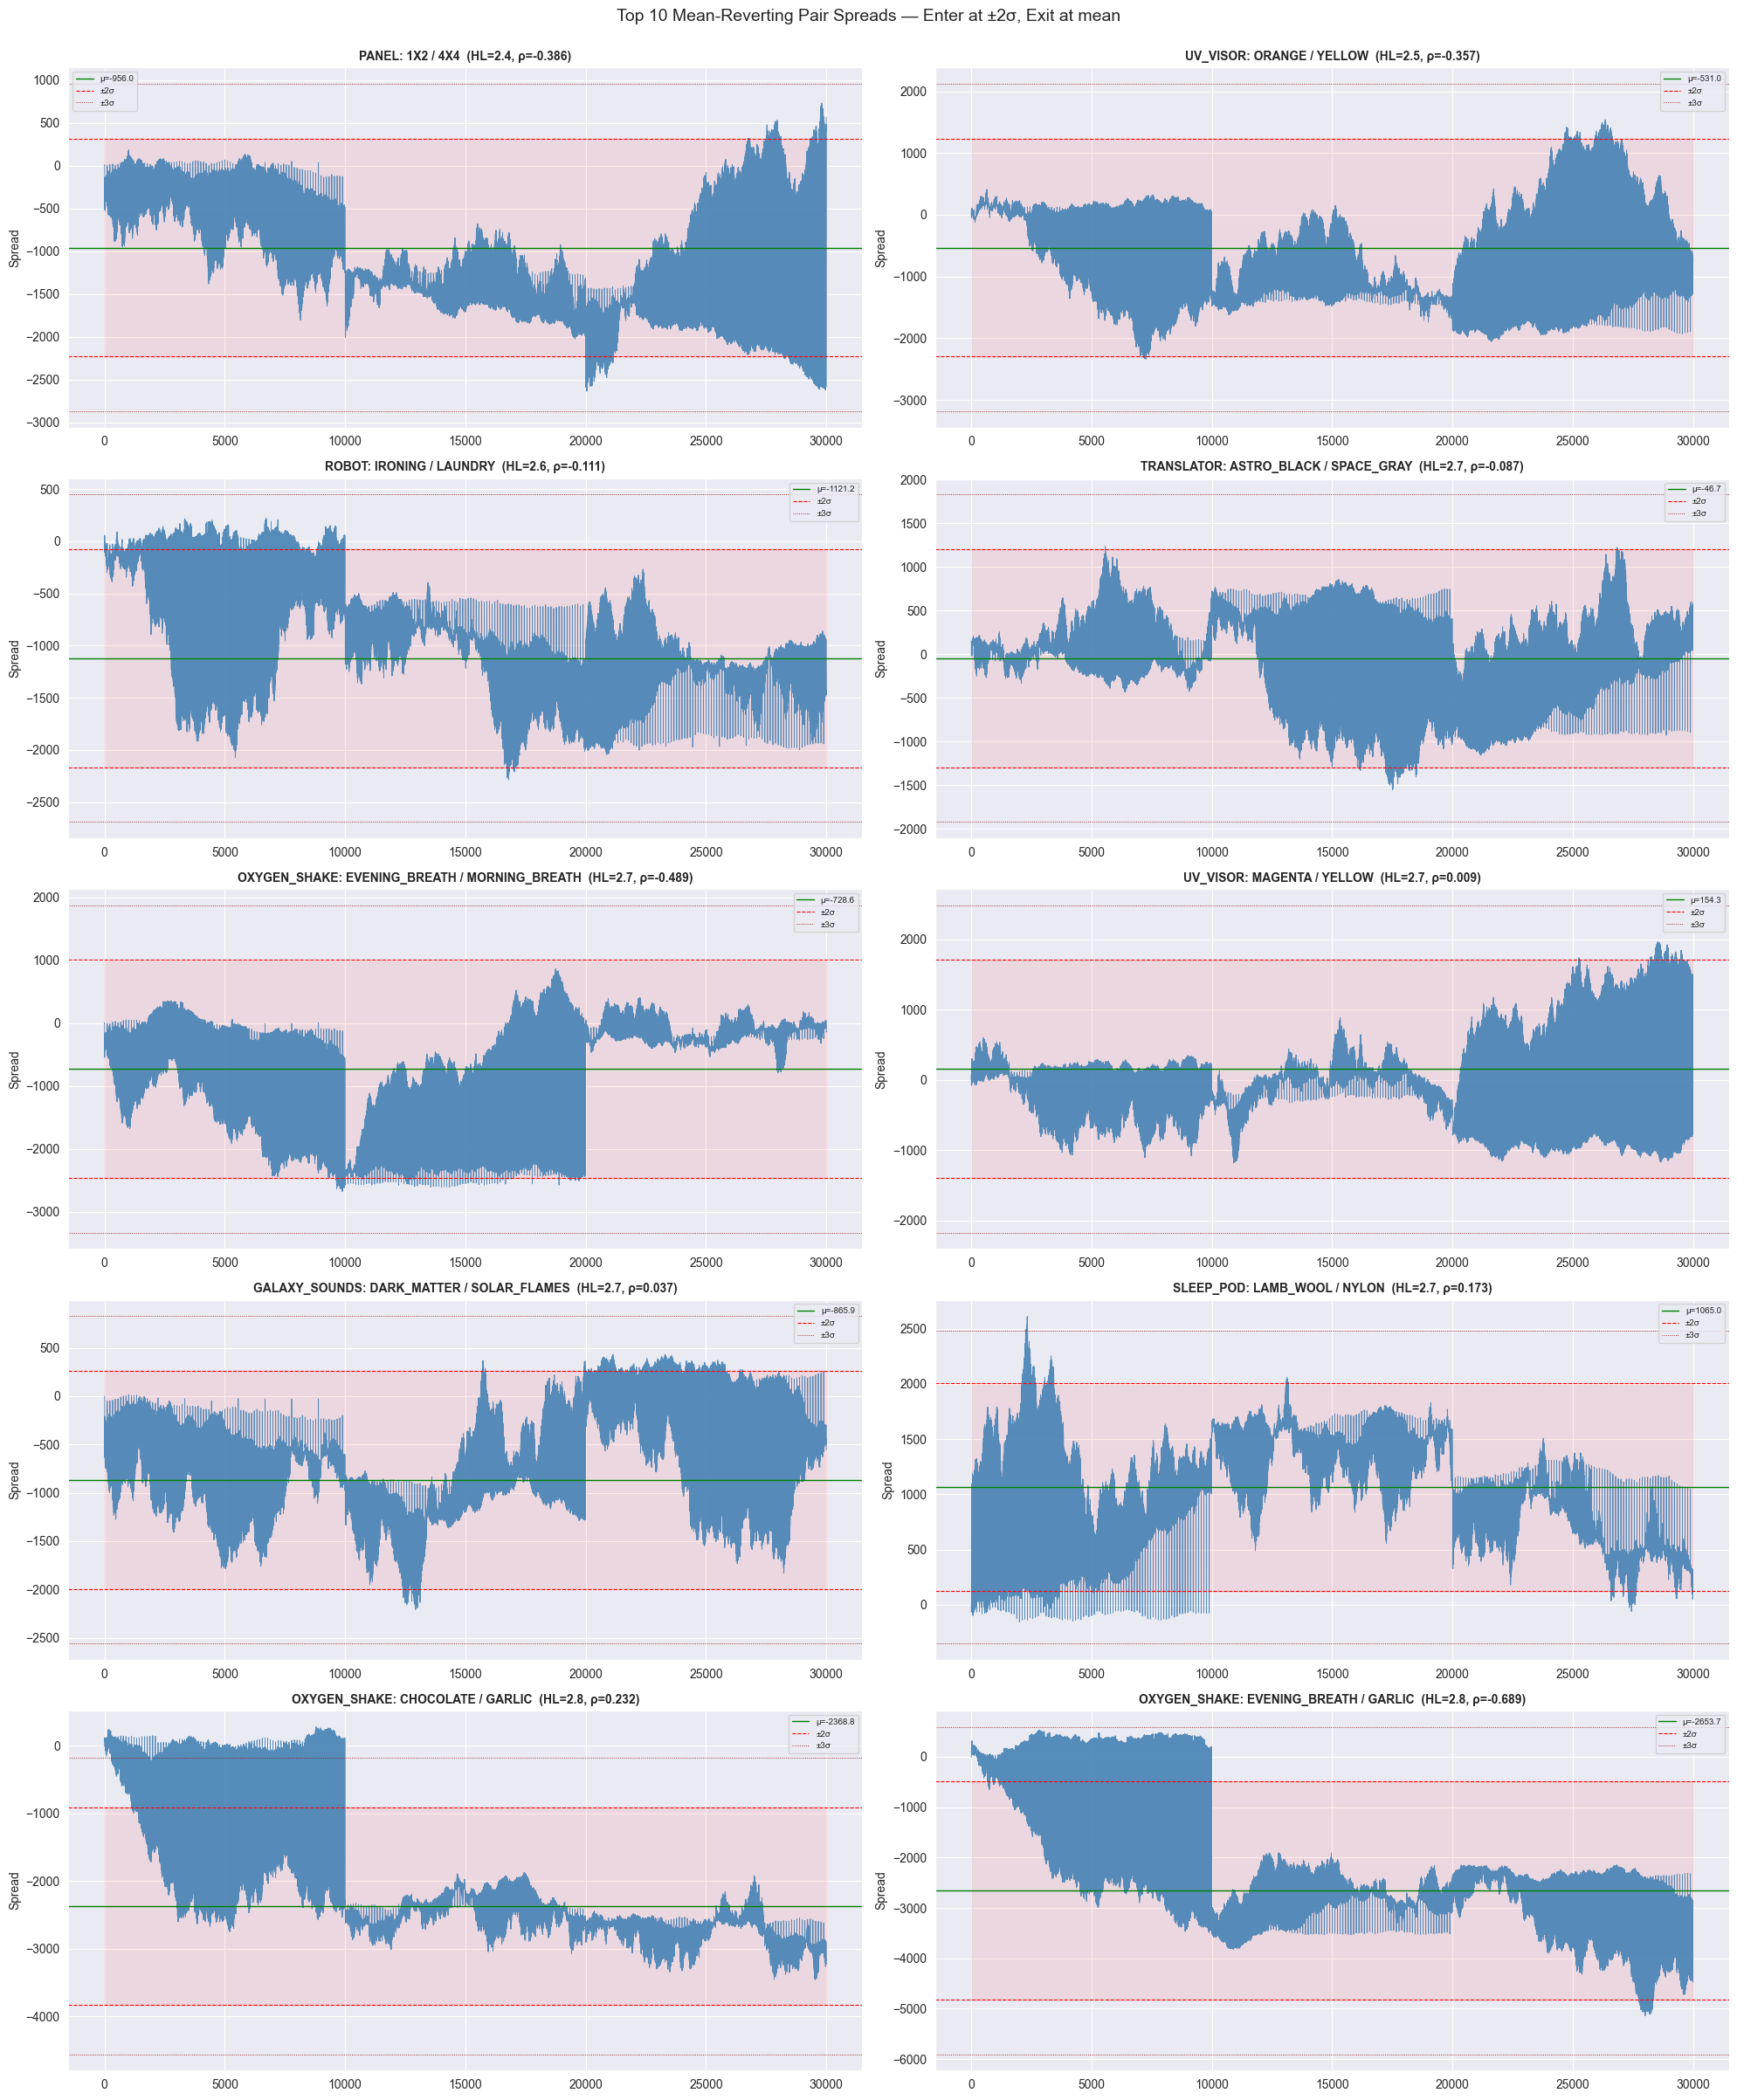

In [18]:
top_pairs = good_pairs.head(10)

fig, axes = plt.subplots(5, 2, figsize=(20, 24))
axes = axes.flatten()

for idx, (_, row) in enumerate(top_pairs.iterrows()):
    if idx >= 10: break
    ax = axes[idx]
    spread = mid[row['p1']] - mid[row['p2']]
    mu, sigma = spread.mean(), spread.std()
    
    ax.plot(spread.values, linewidth=0.6, alpha=0.9, color='steelblue')
    ax.axhline(mu, color='green', ls='-', lw=1, label=f'μ={mu:.1f}')
    ax.axhline(mu + 2*sigma, color='red', ls='--', lw=0.8, label='±2σ')
    ax.axhline(mu - 2*sigma, color='red', ls='--', lw=0.8)
    ax.axhline(mu + 3*sigma, color='darkred', ls=':', lw=0.6, label='±3σ')
    ax.axhline(mu - 3*sigma, color='darkred', ls=':', lw=0.6)
    ax.fill_between(range(len(spread)), mu - 2*sigma, mu + 2*sigma, alpha=0.08, color='red')
    ax.set_title(f"{row['sector']}: {row['pair']}  (HL={row['half_life']:.1f}, ρ={row['return_corr']:.3f})",
                 fontsize=10, fontweight='bold')
    ax.legend(fontsize=7)
    ax.set_ylabel('Spread')

plt.suptitle('Top 10 Mean-Reverting Pair Spreads — Enter at ±2σ, Exit at mean', fontsize=14, y=1.0)
plt.tight_layout()
plt.show()

---
## 15. Strongly Anti-Correlated Pairs — Market-Neutral Opportunities

Pairs with ρ < −0.5 are especially interesting: they naturally hedge each other.  
Combined with fast mean-reversion → high-confidence stat-arb.


In [ ]:
anti_pairs = pairs_df[pairs_df['return_corr'] < -0.5].sort_values('return_corr')

print(f"═══ Strongly Anti-Correlated Pairs (ρ < −0.5): {len(anti_pairs)} found ═══\n")
print(anti_pairs[['sector', 'pair', 'return_corr', 'half_life', 'spread_std', 'spread_range']]
      .to_string(index=False))

if len(anti_pairs) > 0:
    n_plot = min(8, len(anti_pairs))
    fig, axes = plt.subplots(n_plot // 2 + n_plot % 2, 2, figsize=(18, 4 * (n_plot // 2 + n_plot % 2)))
    axes = axes.flatten() if n_plot > 2 else [axes] if n_plot == 1 else axes.flatten()
    
    for idx, (_, row) in enumerate(anti_pairs.head(n_plot).iterrows()):
        ax = axes[idx]
        # Plot both products normalised
        n1 = mid[row['p1']] / mid[row['p1']].iloc[0] * 100
        n2 = mid[row['p2']] / mid[row['p2']].iloc[0] * 100
        ax.plot(n1.values, label=row['p1'].split('_')[-1], alpha=0.8, linewidth=0.7)
        ax.plot(n2.values, label=row['p2'].split('_')[-1], alpha=0.8, linewidth=0.7)
        ax.set_title(f"{row['sector']}: {row['pair']}  ρ={row['return_corr']:.3f}",
                     fontsize=10, fontweight='bold')
        ax.legend(fontsize=8)
        ax.set_ylabel('Normalised')
    
    for j in range(idx + 1, len(axes)):
        axes[j].set_visible(False)
    
    plt.suptitle('Anti-Correlated Pairs — One goes up, the other goes down', fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()

---
## 16. Cross-Sector ETF Correlations — Portfolio Construction

In [ ]:
etf_corr = etf_returns.corr()

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(etf_corr, annot=True, fmt='.3f', cmap='RdYlGn', center=0,
            vmin=-1, vmax=1, ax=ax, square=True)
ax.set_title('Cross-Sector ETF Return Correlations', fontsize=14)
plt.tight_layout()
plt.show()

etf_corr_ut = etf_corr.where(np.triu(np.ones_like(etf_corr, dtype=bool), k=1))
stacked = etf_corr_ut.stack().sort_values(ascending=False)

print("\n═══ Most CORRELATED sector pairs ═══")
for (s1, s2), v in stacked.head(5).items():
    print(f"  {s1:25s} / {s2:25s}  ρ = {v:+.4f}")
print("\n═══ Most ANTI-CORRELATED sector pairs ═══")
for (s1, s2), v in stacked.tail(5).items():
    print(f"  {s1:25s} / {s2:25s}  ρ = {v:+.4f}")
print("\nAnti-correlated sectors → good for cross-sector hedging")

---
## 17. Rolling Volatility (w=500) — Regime Detection

In [ ]:
window = 500
rolling_vol = returns.rolling(window).std() * np.sqrt(10000)

fig, axes = plt.subplots(5, 2, figsize=(20, 28))
axes = axes.flatten()

for i, sector in enumerate(sectors):
    ax = axes[i]
    members = sorted([p for p in products if sector_map[p] == sector])
    for m in members:
        label = m.replace(sector + '_', '')
        ax.plot(rolling_vol[m].values, label=label, alpha=0.8, linewidth=0.7)
    ax.set_title(f'{sector} — Rolling Vol (w={window})', fontsize=12, fontweight='bold')
    ax.legend(fontsize=7, loc='best')
    ax.set_ylabel('Annualised Vol')

plt.suptitle('Rolling Volatility — Spot regime changes & vol clustering', fontsize=16, y=1.0)
plt.tight_layout()
plt.show()

---
## 18. Bid-Ask Spread & Liquidity Analysis

In [ ]:
raw['ba_spread'] = raw['ask_price_1'] - raw['bid_price_1']
raw['ba_spread_bps'] = raw['ba_spread'] / raw['mid_price'] * 10000

ba_stats = raw.groupby('product')['ba_spread_bps'].agg(['mean', 'std', 'median']).reset_index()
ba_stats.columns = ['product', 'ba_mean_bps', 'ba_std_bps', 'ba_median_bps']
ba_stats['sector'] = ba_stats['product'].map(sector_map)
ba_stats = ba_stats.sort_values(['sector', 'ba_mean_bps'])

print("═══ Bid-Ask Spread (basis points) ═══\n")
print(ba_stats[['product', 'sector', 'ba_mean_bps', 'ba_std_bps', 'ba_median_bps']].to_string(index=False))

fig, ax = plt.subplots(figsize=(18, 7))
x = range(len(ba_stats))
colors_ba = [sector_color[ba_stats.iloc[j]['sector']] for j in range(len(ba_stats))]
ax.bar(x, ba_stats['ba_mean_bps'], color=colors_ba, alpha=0.8)
ax.set_xticks(list(x))
ax.set_xticklabels([p.split('_')[-1][:8] for p in ba_stats['product']], rotation=90, fontsize=7)
ax.set_ylabel('Bid-Ask Spread (bps)')
ax.set_title('Bid-Ask Spread by Product (colored by sector)', fontsize=14)
plt.tight_layout()
plt.show()

print("\nTrading cost matters! A round-trip costs ~2× the spread.")
print("Only trade pairs where expected profit > round-trip BA cost.")

---
## 19. Order Book Depth

In [ ]:
raw['total_bid_vol'] = raw[['bid_volume_1', 'bid_volume_2', 'bid_volume_3']].sum(axis=1)
raw['total_ask_vol'] = raw[['ask_volume_1', 'ask_volume_2', 'ask_volume_3']].sum(axis=1)
raw['total_book_vol'] = raw['total_bid_vol'] + raw['total_ask_vol']

vol_stats = raw.groupby('product').agg(
    avg_bid_l1=('bid_volume_1', 'mean'),
    avg_ask_l1=('ask_volume_1', 'mean'),
    avg_total_book=('total_book_vol', 'mean'),
).reset_index()
vol_stats['sector'] = vol_stats['product'].map(sector_map)
vol_stats['imbalance'] = (vol_stats['avg_bid_l1'] - vol_stats['avg_ask_l1']) / (vol_stats['avg_bid_l1'] + vol_stats['avg_ask_l1'])
vol_stats = vol_stats.sort_values(['sector', 'avg_total_book'], ascending=[True, False])

print("═══ Order Book Depth ═══\n")
print(vol_stats.to_string(index=False))

fig, ax = plt.subplots(figsize=(18, 7))
x = range(len(vol_stats))
colors_v = [sector_color[vol_stats.iloc[j]['sector']] for j in range(len(vol_stats))]
ax.bar(x, vol_stats['avg_total_book'], color=colors_v, alpha=0.8)
ax.set_xticks(list(x))
ax.set_xticklabels([p.split('_')[-1][:8] for p in vol_stats['product']], rotation=90, fontsize=7)
ax.set_ylabel('Avg Total Book Volume')
ax.set_title('Order Book Depth by Product (colored by sector)', fontsize=14)
plt.tight_layout()
plt.show()

---
## 20. Lead-Lag Analysis — Does any product predict others?

In [ ]:
max_lag = 20
lead_lag_results = []

for sector in sectors:
    members = sorted([p for p in products if sector_map[p] == sector])
    for p1, p2 in combinations(members, 2):
        r1 = returns[p1].values
        r2 = returns[p2].values
        
        best_lag, best_corr = 0, np.corrcoef(r1, r2)[0, 1]
        
        for lag in range(-max_lag, max_lag + 1):
            if lag == 0: continue
            if lag > 0:
                c = np.corrcoef(r1[lag:], r2[:-lag])[0, 1]
            else:
                c = np.corrcoef(r1[:lag], r2[-lag:])[0, 1]
            if abs(c) > abs(best_corr):
                best_corr, best_lag = c, lag
        
        lead_lag_results.append({
            'sector': sector,
            'p1': p1.replace(sector+'_', ''),
            'p2': p2.replace(sector+'_', ''),
            'lag0_corr': np.corrcoef(r1, r2)[0, 1],
            'best_lag': best_lag,
            'best_corr': best_corr,
            'improvement': abs(best_corr) - abs(np.corrcoef(r1, r2)[0, 1])
        })

ll_df = pd.DataFrame(lead_lag_results)
sig_ll = ll_df[ll_df['improvement'] > 0.005].sort_values('improvement', ascending=False)

print("═══ Lead-Lag Relationships (where shifted corr > contemporaneous) ═══\n")
if len(sig_ll) > 0:
    print(sig_ll.head(25).to_string(index=False))
    print(f"\nTotal pairs with significant lead-lag: {len(sig_ll)}")
    print("\nPositive best_lag means p1 LEADS p2 by that many ticks")
    print("Negative best_lag means p2 LEADS p1")
else:
    print("No significant lead-lag relationships found.")

---
## 21. Sector Price-Sum Analysis — Is the sector total conserved?

If the sum of prices within a sector stays roughly constant, this confirms  
a **zero-sum rotation** game and makes the trading strategy clear.


In [ ]:
fig, axes = plt.subplots(5, 2, figsize=(20, 28))
axes = axes.flatten()

print("═══ Sector Price-Sum Statistics ═══\n")
for i, sector in enumerate(sectors):
    ax = axes[i]
    members = sorted([p for p in products if sector_map[p] == sector])
    sector_sum = mid[members].sum(axis=1)
    cv = sector_sum.std() / sector_sum.mean()
    
    ax.plot(sector_sum.values, linewidth=0.8, color='navy')
    ax.axhline(sector_sum.mean(), color='red', ls='--', lw=1)
    ax.set_title(f'{sector} — Sum of all 5 prices (CV={cv:.4f})', fontsize=12, fontweight='bold')
    ax.set_ylabel('Price Sum')
    
    print(f"  {sector:25s}  mean={sector_sum.mean():10.1f}  std={sector_sum.std():8.1f}  "
          f"CV={cv:.4f}  range={sector_sum.max()-sector_sum.min():.1f}")

plt.suptitle('Sector Price Sums — Low CV means near-conservation (zero-sum game)', fontsize=15, y=1.0)
plt.tight_layout()
plt.show()

print("\nIf CV is very low (<0.01), the sector is nearly zero-sum:")
print("  → When one product goes up by X, others go down by ~X total.")
print("  → Strategy: track the sum, trade deviations from individual fair shares.")

---
## 22. Actionable Trading Summary

### Key Structural Findings

1. **Negative intra-sector correlations dominate** — this is NOT a typical equity market. Products within each sector tend to move against each other.

2. **Very short half-lives (3–20 ticks)** — spreads mean-revert fast, enabling high-frequency stat-arb.

3. **Sector sums** — check if they're roughly constant. If so, the game is explicitly zero-sum within sectors.

### Strategy Framework

| Strategy | When | How |
|----------|------|-----|
| **Pair Spread** | HL < 10, \|ρ\| > 0.5 | Enter at ±2σ, exit at mean. Size inversely to spread_std. |
| **ETF Spread** | Product deviates from sector ETF | Long undervalued, short ETF (or vice versa). |
| **Cross-Sector Hedge** | Anti-correlated sector ETFs | Long one sector ETF, short another for market-neutral PnL. |
| **Lead-Lag Alpha** | Significant lagged correlation | Trade the lagging product in direction of the leading signal. |

### Cost Check
Always compare expected reversion profit against **2× bid-ask spread** (round-trip cost).  
Prioritize pairs/products with tighter BA spreads and deeper books.
